# IEMOCAP 이산·연속 감정 인식 평가
## 학습 완료 모델을 이용한 5겹 교차검증 현장 시연

**목적:** 이산 감정 클래스 및 정서가·각성도 예측을 IEMOCAP의 원본 사람 주석(정답)과 비교함.
각 폴드에서 학습·개발에 사용하지 않은 세션만 해당 폴드의 가중치로 추론함.

**단계 설명 → 함수와 입력·출력 → 코드 실행 → 결과 확인** 순서로 구성했음.
코드 셀을 위에서부터 `Shift+Enter`로 실행함. 표·그래프는 해당 셀 아래에서 확인함.

| 순서 | 현장에서 확인할 내용 |
|---|---|
| 1. 실행 준비 | 라이브러리, 경로, 파일 무결성 |
| 2. 평가 데이터·미디어·전처리 | 원본 정답, 음성·텍스트·영상 재생, 전처리 및 특징 추출 |
| 3. 5겹 교차검증 평가 조건 | 학습·개발·시험 세션과 가중치 선택 기록 |
| 4. 한 대화 추론 | 모델 로딩 → 저장 통계로 정규화 → 실제 순전파 → 정답 비교 |
| 5. 전체 5겹 교차검증 평가 | 10개 가중치 추론, 폴드별 점수, 평균±표본표준편차 |
| 6. 결과 시각화 | 폴드별 성능, 한 대화의 V/A 정답·예측 |
| 7. 독립 검증과 결과 보존 | 별도 채점, 출력 파일 확인 |

**준비된 모델:** Base `InductiveGraph(multi_graph, observed gate)`. 7분류와 V/A 회귀는 각각 학습한 별도 모델임.
현장에서는 학습 완료 가중치 로딩·추론·채점을 수행함. IEMOCAP 원본 사람 주석을 정답으로 사용함.
입력은 사전 추출한 음성·운율·텍스트·영상 특징임. 예시 대화의 원본 미디어와 전처리 중간 결과를 함께 확인함.

**실행 환경:** Python 3.10, 패키지 폴더 전체, `requirements.txt`의 패키지가 필요함.
방문 전에 `python -m pip install -r requirements.txt`로 준비하고 그 Python 환경을 노트북 커널로 선택함.
CPU 4스레드가 기본임. 실행 중 오류가 발생하면 원인을 해결한 뒤 해당 단계부터 다시 실행함.


**용어 안내**

설명에서는 아래 한국어 표현을 사용함. 코드의 변수·함수 이름과 저장된 결과의 항목명은 원래 표기를 유지함.

| 설명에서 사용하는 말 | 코드·결과의 영문 표기 | 의미 |
|---|---|---|
| 정답 | `Ground Truth` | IEMOCAP에 포함된 사람 주석 |
| 정서가 | `Valence` | 감정의 긍정·부정 정도 |
| 각성도 | `Arousal` | 정서적 활성 정도 |
| 정확도 | `Accuracy` | 채점 대상 중 예측이 정답과 일치한 비율 |
| 가중 F1 | `Weighted F1` | 클래스별 정답 표본 수를 반영한 F1 |
| 폴드 | `Fold` | 교차검증에서 학습·개발·시험 자료를 나누는 한 구성 |
| 세션 | `Session` | IEMOCAP의 녹화 회차 구분 |
| 에포크 | `epoch` | 학습 자료 전체를 한 번 사용하는 학습 반복 단위 |

**전처리 예시:** 2-4~2-12절은 약 9.81초 길이의 `Ses01F_impro01_F011`을 사용함. 같은 발화의 원문·음성·영상에 공통 전처리 절차를 적용함.


# 1. 실행 준비
## 1-1. 라이브러리 선언

`numpy`는 특징·예측 배열, `torch`는 모델 추론, `matplotlib`은 결과 그래프,
`sklearn.metrics`는 분류 지표의 독립 계산에 사용함. `IPython.display`는 표·그림을 셀 아래에 표시함.

**확인:** 현재 커널의 Python 경로와 라이브러리 버전이 출력되어야 함.


In [1]:
# 1-1. 추론·채점·표·그래프 출력에 사용할 라이브러리를 준비함.
# 노트북 출력의 Python 경로로 현재 선택한 커널 환경을 확인할 수 있음.
from pathlib import Path
from datetime import datetime, timedelta, timezone
import sys, json, csv, html
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score
from IPython.display import display, HTML, Image

# 패키지 폴더에 자동 바이트코드 파일을 만들지 않고 CPU 스레드를 4개로 고정함.
sys.dont_write_bytecode = True
torch.set_num_threads(4)
print("Python:", sys.executable)
print("torch:", torch.__version__, "| numpy:", np.__version__)


Python: /home/neuroai-server05/PycharmProjects/ICASSP_Hetero/.venv-emotionheart/bin/python
torch: 2.7.1+cu118 | numpy: 1.23.5


## 1-2. 패키지 경로와 표 출력 함수

노트북이 있는 `IEMOCAP_Official_Demo` 폴더에서 실행함. 프로젝트 폴더나 `공인인증` 폴더에서 시작한 경우도 자동으로 찾음.
`run_demo.py`는 전체 추론, `audit_demo.py`는 별도 구현을 이용한 결과 검증 코드임.

### 함수 `show_table`
- **기능:** 딕셔너리 목록을 노트북 HTML 표로 표시함.
- **입력 인자:** `rows` — 행 목록, `columns` — 표시할 열 목록(생략하면 첫 행의 열 사용), `limit` — 표시 행 수.
- **반환값:** 반환값 없이 표를 셀 아래에 표시함. 숫자·문자열을 HTML 이스케이프해 표시함.

**확인:** 패키지 경로와 7개 감정의 클래스 번호가 출력됨. 학습 때 정한 클래스 순서를 유지함.


In [2]:
# 1-2. 패키지를 다른 PC로 옮기거나 results 폴더에서 열어도 실행 위치를 찾음.
# 현재 폴더와 상위 폴더에서 run_demo.py가 있는 패키지 루트를 검색함.
candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / "IEMOCAP_Official_Demo",
              Path.cwd() / "공인인증" / "IEMOCAP_Official_Demo"]
ROOT = next((p.resolve() for p in candidates if (p / "run_demo.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("IEMOCAP_Official_Demo 폴더에서 노트북을 시작하세요.")
sys.path.insert(0, str(ROOT))
import run_demo as demo
import audit_demo
# 이전에 다른 패키지에서 불러온 모듈이 남아 있으면 혼용하지 않고 중단함.
assert demo.ROOT == ROOT and audit_demo.ROOT == ROOT
DEVICE = "cpu"
KST = timezone(timedelta(hours=9))
CLASS_NAMES = dict(zip(demo.CLASSES, demo.KOREAN))

# 표 출력 함수: rows는 행 딕셔너리 목록, columns는 열 순서, limit는 표시할 행 수임.
# 표를 셀 아래에 표시하고 반환값은 없음. 원래 데이터의 내용과 순서를 유지함.
def show_table(rows, columns=None, limit=None):
    rows = list(rows)
    if not rows:
        print("표시할 행이 없습니다.")
        return
    columns = list(rows[0]) if columns is None else columns
    shown = rows if limit is None else rows[:limit]
    # 문자열을 HTML 이스케이프하여 발화 텍스트 등이 태그로 해석되지 않도록 함.
    header = "".join("<th>" + html.escape(str(c)) + "</th>" for c in columns)
    body = "".join("<tr>" + "".join("<td>" + html.escape(str(r[c])) + "</td>" for c in columns) + "</tr>" for r in shown)
    display(HTML('<div style="overflow-x:auto"><table border="1" cellpadding="6"><thead><tr>' + header + '</tr></thead><tbody>' + body + '</tbody></table></div>'))
    if limit is not None:
        print(f"전체 {len(rows):,}행 중 앞 {len(shown):,}행 표시")

print("Package:", ROOT)
# 감정 클래스 번호는 학습 때의 출력 순서를 유지함.
show_table([{"클래스": i, "원본 코드": name, "감정": CLASS_NAMES[name]} for i, name in enumerate(demo.CLASSES)])


Package: /tmp/iemocap_notebook_mwgi2tia/IEMOCAP_Official_Demo


클래스,원본 코드,감정
0,hap,행복
1,sad,슬픔
2,ang,분노
3,fea,공포
4,sur,놀람
5,dis,혐오
6,neu,중립


## 1-3. 평가 파일 사전 검사

### 함수 `demo.verify`
- **기능:** 가중치·특징·원본 주석의 해시, 폴드 분리, 개발 자료를 기준으로 한 모델 선택과 정답 정렬을 검사함.
- **입력 인자:** `audit_normalizers=False` — 기본은 저장된 학습 자료의 정규화 통계를 검증함. `True`는 학습 자료 특징으로 통계를 읽기 전용 재검산함.
- **반환값:** `verification`(검사 결과), `datasets`(과제별 정답 정의), `protocols`(폴드와 모델 설정), `original`(원본 발화 정보).

**확인:** “검사 통과”가 `True`이고 모델 저장 파일 10개, 원본 주석 10,039개가 표시됨. 검사 통과 후 추론을 진행함.
노트북 실행 결과·셀 번호의 자동 저장은 허용하고 코드·설명 셀 변경은 검사함.


In [3]:
# 1-3. 추론 전에 전달 파일, 원본 정답, 폴드 분리 및 모델 선택 이력을 검사함.
# 검사 중 불일치가 발견되면 예외로 중단하므로 이후 결과를 생성하지 않음.
# 반환값은 검사 보고서, 과제별 정답 정의, 평가 설정, 원본 대화 정보 순서임.
verification, datasets, protocols, original = demo.verify()
assert verification["passed"]
show_table([{"검사 통과": verification["passed"], "체크포인트 수": verification["folds_checked"],
             "원본 주석 수": verification["annotations_checked"], "검사 파일 수": verification["files_checked"]}])


검사 통과,체크포인트 수,원본 주석 수,검사 파일 수
True,10,10039,578


# 2. 평가 데이터와 정답 준비
## 2-1. 멀티모달 특징 구성 확인

151개 대화, 10,039개 발화의 특징 캐시를 사용함. 각 대화의 모든 발화를 문맥으로 유지하고 대화별로 독립 처리함.

| 입력 | 특징 | 발화당 차원 |
|---|---|---:|
| 음성 | 고정 WavLM의 평균·표준편차 | 1536 |
| 운율 | 음성에서 추출한 통계 | 16 |
| 텍스트 | 고정 RoBERTa 표현 | 768 |
| 영상 | 고정 ResNet18 표현 | 512 |

**실행 내용:** 세션별 대화 수와 전체 문맥 발화 수를 집계함. 이 개수는 채점 대상 수와 구분함.


In [4]:
# 2-1. 세션별 대화와 문맥 발화의 수를 집계함.
# 분류 채점에서 제외되는 감정도 문맥에는 남으므로 이 수는 채점 표본 수와 다름.
session_rows = []
for session in range(1, 6):
    dialogues = [d for d in original.values() if d["session"] == session]
    session_rows.append({"Session": session, "대화 수": len(dialogues),
                         "문맥 발화 수": sum(len(d["utterances"]) for d in dialogues)})
show_table(session_rows)
# 전체 대화와 발화의 누락 여부를 확인함.
assert sum(r["대화 수"] for r in session_rows) == 151
assert sum(r["문맥 발화 수"] for r in session_rows) == 10039


Session,대화 수,문맥 발화 수
1,28,1819
2,30,1811
3,32,2136
4,30,2103
5,31,2170


## 2-2. 원본 정답 주석 읽기

정답은 **IEMOCAP에 포함된 사람 주석**임.
원본 주석에서 발화 ID, 감정 클래스, 정서가(`Valence`), 활성도(`Activation`)를 읽음.
원본의 활성도는 이 평가에서 각성도로 표기함.

**실행 내용:** 1번 폴드의 첫 번째 시험 대화를 예시로 고정하고 원본 헤더와 평가 정의를 나란히 출력함.
예시 대화는 예측 결과를 확인하기 전에 평가 정의의 순서에 따라 고정함.

**확인:** 발화 ID와 원본 감정·V/A가 평가 정의에 일치해야 함.


In [5]:
# 2-2. 예측 결과를 보기 전에 1번 폴드의 첫 시험 대화를 예시로 고정함.
# 평가 설정에 저장된 대화 순서에 따라 예시를 선택함.
EXAMPLE_FOLD = 1
example_split = protocols["classification"]["folds"][EXAMPLE_FOLD - 1]
EXAMPLE_DIALOGUE = example_split["test"][0]
# 과제별 평가 정의를 대화 ID로 바로 찾을 수 있게 색인함.
descriptor_index = {task: {d["id"]: d for d in datasets[task]["dialogues"]} for task in demo.TASKS}
annotation_path = ROOT / "data/annotations" / f"Session{EXAMPLE_FOLD}" / f"{EXAMPLE_DIALOGUE}.txt"
# 원본 파일에서 발화 구간·감정·V/A가 기록된 헤더 행만 확인함.
headers = [line for line in annotation_path.read_text(encoding="utf-8-sig").splitlines() if line.startswith("[")]
print("예시 대화:", EXAMPLE_DIALOGUE)
print("원본 주석:", annotation_path.relative_to(ROOT))
print("\n".join(headers[:5]))
ground_truth_rows = []
for u, c, v in zip(original[EXAMPLE_DIALOGUE]["utterances"],
                   descriptor_index["classification"][EXAMPLE_DIALOGUE]["utterances"],
                   descriptor_index["va"][EXAMPLE_DIALOGUE]["utterances"]):
    # 세 자료의 발화 ID가 같은 순서인지 검사하여 다른 발화의 정답이 연결되는 것을 막음.
    assert u["id"] == c["id"] == v["id"]
    ground_truth_rows.append({"발화 ID": u["id"], "원본 감정": u["original_emotion"],
                              "분류 정답 번호": c["target"], "Valence GT": v["target"][0], "Arousal GT": v["target"][1]})
show_table(ground_truth_rows, limit=5)


예시 대화: Ses01F_impro01
원본 주석: data/annotations/Session1/Ses01F_impro01.txt
[6.2901 - 8.2357]	Ses01F_impro01_F000	neu	[2.5000, 2.5000, 2.5000]
[10.0100 - 11.3925]	Ses01F_impro01_F001	neu	[2.5000, 2.5000, 2.5000]
[14.8872 - 18.0175]	Ses01F_impro01_F002	neu	[2.5000, 2.5000, 2.5000]
[19.2900 - 20.7875]	Ses01F_impro01_F003	xxx	[2.5000, 3.0000, 3.0000]
[21.3257 - 24.7400]	Ses01F_impro01_F004	xxx	[2.5000, 3.0000, 2.5000]


발화 ID,원본 감정,분류 정답 번호,Valence GT,Arousal GT
Ses01F_impro01_F000,neu,6,2.5,2.5
Ses01F_impro01_M000,fru,-100,2.5,2.0
Ses01F_impro01_F001,neu,6,2.5,2.5
Ses01F_impro01_M001,fru,-100,2.5,2.0
Ses01F_impro01_F002,neu,6,2.5,2.5


전체 30행 중 앞 5행 표시


## 2-3. 이산·연속 감정의 채점 대상 확인

- **분류:** `hap/sad/ang/fea/sur/dis/neu` 4,639개만 채점함. 그 밖의 원본 감정은 `-100`으로 표시하여 채점에서 제외하고 대화 문맥은 유지함.
- **회귀:** 원본 V/A의 두 값이 모두 1~5인 10,035쌍만 채점함. 정서가 5.5인 4개 발화는 원값을 보존하고 두 차원 모두 제외함.
- **정답 기준:** 이산 감정과 V/A의 원본 주석을 각각 사용함.

**확인:** 클래스별 표본 수 합계 4,639, 유효 V/A 10,035, 범위 밖 V/A 4가 출력됨.


In [6]:
# 2-3. 이산 감정과 연속 감정의 채점 대상을 각각 집계함.
# 분류의 -100은 원본 7개 감정 외 라벨을 뜻하며 채점에서 제외하고 문맥에는 유지함.
class_targets = np.asarray([u["target"] for d in datasets["classification"]["dialogues"] for u in d["utterances"]])
support = np.bincount(class_targets[class_targets != -100], minlength=7)
show_table([{"감정": CLASS_NAMES[name], "코드": name, "채점 표본 수": int(support[i])} for i, name in enumerate(demo.CLASSES)])
va_records = [u for d in datasets["va"]["dialogues"] for u in d["utterances"]]
va_targets = np.asarray([u["target"] for u in va_records])
# 정서가와 각성도가 모두 1~5인 발화만 두 차원의 채점에 함께 포함함.
# 연속 감정 정답은 원본 V/A 값을 보존하고 유효 범위 마스크를 적용함.
va_valid = ((va_targets >= 1) & (va_targets <= 5)).all(1)
print("분류 채점:", int(support.sum()), "| V/A 채점:", int(va_valid.sum()), "| V/A 제외:", int((~va_valid).sum()))
show_table([{"제외 발화 ID": u["id"], "원본 Valence": u["target"][0], "원본 Arousal": u["target"][1]} for u, valid in zip(va_records, va_valid) if not valid])
assert int(support.sum()) == 4639 and int(va_valid.sum()) == 10035


감정,코드,채점 표본 수
행복,hap,595
슬픔,sad,1084
분노,ang,1103
공포,fea,40
놀람,sur,107
혐오,dis,2
중립,neu,1708


분류 채점: 4639 | V/A 채점: 10035 | V/A 제외: 4


제외 발화 ID,원본 Valence,원본 Arousal
Ses03M_impro07_M003,5.5,5.0
Ses03M_impro07_M010,5.5,5.0
Ses03M_impro07_M013,5.5,5.0
Ses03M_impro07_M021,5.5,5.0


## 2-4. 시험 발화와 원문 확인

약 9.81초 길이의 `Ses01F_impro01_F011`을 예시로 사용함. 음성·영상·원문·전처리와 예측 비교에 같은 발화 ID를 사용함.

### 함수 `load_media_example`
- **기능:** 준비된 미디어의 대화·세션·시험 폴드, 원본 메타데이터, 파일 경로·크기·해시를 검사하고 선택한 자료를 반환함.
- **입력 인자:** `dialogue_id` — 선택 발화가 포함된 시험 대화 ID.
- **반환값:** 선택 발화 정보, 원본 음성 경로, 재생 영상 경로, 미디어 준비 기록.

**확인:** 선택 발화의 ID·시각·화자·원문이 한 행으로 표시됨. 재생 자료는 패키지의 `data/media`에서 읽음.


In [7]:
# 2-4. 원문·음성·영상·전처리에 사용할 예시를 발화 ID로 지정함.
import re
EXAMPLE_UTTERANCE_ID = "Ses01F_impro01_F011"
EXAMPLE_INDEX = next(i for i, row in enumerate(original[EXAMPLE_DIALOGUE]["utterances"])
                     if row["id"] == EXAMPLE_UTTERANCE_ID)

# 입력은 선택 발화가 포함된 대화 ID임. 원본의 발화 ID·텍스트·시각·화자로 재생 자료를 확인함.
# 반환값은 선택 발화 정보, 음성 경로, 영상 경로, 전체 미디어 목록 순서임.
def load_media_example(dialogue_id):
    index = EXAMPLE_INDEX
    if not isinstance(dialogue_id, str) or re.fullmatch(r"[A-Za-z0-9_]+", dialogue_id) is None:
        raise ValueError("대화 ID 형식이 잘못됨")
    if dialogue_id not in original:
        raise ValueError(f"원본 목록에 없는 대화임: {dialogue_id}")
    source_dialogue = original[dialogue_id]
    source_rows = source_dialogue["utterances"]
    if type(index) is not int or not 0 <= index < len(source_rows):
        raise ValueError(f"발화 선택 번호는 0~{len(source_rows) - 1}의 정수여야 함")
    session = source_dialogue["session"]
    if type(session) is not int or session != EXAMPLE_FOLD:
        raise ValueError("선택 대화의 세션과 예시 시험 폴드가 다름")
    for task in ("classification", "va"):
        splits = [fold for fold in protocols[task]["folds"] if fold["fold"] == EXAMPLE_FOLD]
        if len(splits) != 1:
            raise ValueError(f"시험 폴드 기록을 확인할 수 없음: {task}")
        split = splits[0]
        if dialogue_id not in split["test"] or dialogue_id in split["train"] + split["dev"]:
            raise ValueError(f"해당 모델의 시험 대화가 아님: {task}/{dialogue_id}")

    # 파일을 현재 패키지의 미디어 폴더에서만 읽으며 고정 평가 설정의 해시도 대조함.
    package_root = demo.ROOT.resolve()
    media_root = (package_root / "data/media").resolve()
    if not media_root.is_relative_to(package_root):
        raise ValueError("미디어 폴더가 현재 패키지 밖으로 연결되어 있음")
    bundle_root = (media_root / dialogue_id).resolve()
    if not bundle_root.is_relative_to(media_root):
        raise ValueError("미디어 경로가 패키지의 미디어 폴더를 벗어남")
    manifest_path = (bundle_root / "manifest.json").resolve()
    if not manifest_path.is_relative_to(bundle_root):
        raise ValueError("미디어 목록 경로가 해당 대화 폴더를 벗어남")
    if not manifest_path.is_file():
        raise ValueError(f"재생 자료가 준비되지 않음: {manifest_path}. 현장 방문 전에 준비한 data/media 폴더가 필요함")
    media = json.loads(manifest_path.read_text(encoding="utf-8"))
    if media.get("status") != "complete" or media.get("dialogue_id") != dialogue_id:
        raise ValueError("미디어 준비 상태 또는 대화 ID가 다름")
    if media.get("session") != session or media.get("held_out_fold") != EXAMPLE_FOLD:
        raise ValueError("미디어의 세션·시험 폴드가 평가 설정과 다름")
    if media.get("feature_manifest_sha256") != demo.sha(package_root / "data/features/manifest.json"):
        raise ValueError("미디어 준비에 사용한 특징 목록과 현재 특징 목록이 다름")
    expected_protocols = {task: demo.sha(package_root / "evidence" / task / "protocol.json")
                          for task in ("classification", "va")}
    if media.get("protocol_sha256") != expected_protocols:
        raise ValueError("미디어 준비에 사용한 평가 설정과 현재 평가 설정이 다름")
    rows = media.get("utterances")
    if not isinstance(rows, list) or len(rows) != len(source_rows) or media.get("utterance_count") != len(rows):
        raise ValueError("재생 발화 수가 원본 대화와 다름")

    # 대화 전체의 순서와 파일을 확인한 뒤 선택 발화의 경로를 반환함.
    checked_paths = []
    for entry, source in zip(rows, source_rows):
        if not isinstance(entry, dict) or any(entry.get(key) != source[key] for key in ("id", "text", "start", "end", "speaker")):
            raise ValueError("미디어의 발화 순서·원문·시각·화자가 원본과 다름")
        if entry.get("held_out_fold") != EXAMPLE_FOLD:
            raise ValueError(f"발화의 시험 폴드가 다름: {entry['id']}")
        paths = {}
        for kind, extension in (("audio", "wav"), ("video", "mp4")):
            record = entry.get(kind)
            if not isinstance(record, dict) or record.get("path") != f"{entry['id']}.{extension}":
                raise ValueError(f"재생 파일 이름이 발화 ID와 다름: {entry['id']}/{kind}")
            path = (bundle_root / record["path"]).resolve()
            if not path.is_relative_to(bundle_root) or not path.is_file():
                raise ValueError(f"재생 파일 경로를 확인할 수 없음: {entry['id']}/{kind}")
            if path.stat().st_size != record.get("bytes") or demo.sha(path) != record.get("sha256"):
                raise ValueError(f"재생 파일의 크기 또는 해시가 다름: {entry['id']}/{kind}")
            paths[kind] = path
        if entry["audio"].get("source_sha256") != entry["audio"]["sha256"]:
            raise ValueError(f"원본 음성과 복사본의 해시가 다름: {entry['id']}")
        checked_paths.append(paths)
    return rows[index], checked_paths[index]["audio"], checked_paths[index]["video"], media

MEDIA_EXAMPLE, MEDIA_AUDIO_PATH, MEDIA_VIDEO_PATH, MEDIA_MANIFEST = load_media_example(EXAMPLE_DIALOGUE)
assert MEDIA_EXAMPLE["id"] == EXAMPLE_UTTERANCE_ID
show_table([{"발화 ID": MEDIA_EXAMPLE["id"],
             "화자": "F" if MEDIA_EXAMPLE["speaker"] == 0 else "M",
             "시작 초": MEDIA_EXAMPLE["start"], "종료 초": MEDIA_EXAMPLE["end"],
             "원문": MEDIA_EXAMPLE["text"]}])
# 원문과 ID는 HTML 이스케이프하여 그대로 표시함.
display(HTML('<h3>원문과 발화 정보</h3>'
             + '<p>시험 폴드 ' + html.escape(str(EXAMPLE_FOLD)) + ' · 원본 구간 '
             + html.escape(str(MEDIA_EXAMPLE["start"])) + ' ~ ' + html.escape(str(MEDIA_EXAMPLE["end"])) + '초</p>'
             + '<p style="font-size:1.25em; line-height:1.6; white-space:pre-wrap">' + html.escape(MEDIA_EXAMPLE["text"]) + '</p>'))


발화 ID,화자,시작 초,종료 초,원문
Ses01F_impro01_F011,F,72.45,82.26,"Yes but my wallet was stolen, I don't have anything. I don't have any credit cards, I don't have my ID. Don't you have things on file here?"


## 2-5. 원본 음성 확인

선택 발화 ID에 대응하는 원본 WAV 복사본을 재생함. 음성 파일의 샘플 수·샘플링 주파수·채널 수·재생 시간을 직접 읽어 준비 기록과 대조함.
재생 버튼을 눌러 음성을 듣고 앞에 표시된 원문과 함께 확인함.

### 함수 `Audio`
- **기능:** 선택한 WAV를 노트북 안에 포함하여 재생 버튼을 표시함.
- **입력 인자:** `filename` — 원본 음성 복사본 경로, `embed=True` — 음성 데이터를 출력에 포함함.
- **반환값:** 노트북에서 재생할 수 있는 음성 표시 객체임.

**확인:** 발화 ID와 음성 정보가 표시되고 재생 버튼으로 원본 음성을 들을 수 있음.


In [8]:
# 2-5. 원본 WAV 복사본의 실제 형식을 읽고 기록된 값과 일치하는지 확인함.
import wave
from IPython.display import Audio
with wave.open(str(MEDIA_AUDIO_PATH), "rb") as media_wave:
    MEDIA_AUDIO_INFO = {"frames": media_wave.getnframes(), "sample_rate": media_wave.getframerate(),
                        "channels": media_wave.getnchannels(), "sample_width_bytes": media_wave.getsampwidth()}
if MEDIA_AUDIO_INFO["frames"] <= 0 or MEDIA_AUDIO_INFO["sample_rate"] <= 0:
    raise ValueError("음성 파일의 샘플 수 또는 샘플링 주파수가 잘못됨")
for key, value in MEDIA_AUDIO_INFO.items():
    if MEDIA_EXAMPLE["audio"].get(key) != value:
        raise ValueError(f"원본 음성의 형식과 준비 기록이 다름: {key}")
MEDIA_AUDIO_INFO["duration_seconds"] = MEDIA_AUDIO_INFO["frames"] / MEDIA_AUDIO_INFO["sample_rate"]
if abs(MEDIA_AUDIO_INFO["duration_seconds"] - MEDIA_EXAMPLE["audio"]["duration_seconds"]) > 1 / MEDIA_AUDIO_INFO["sample_rate"]:
    raise ValueError("원본 음성의 재생 시간과 준비 기록이 다름")
show_table([{"발화 ID": MEDIA_EXAMPLE["id"], "재생 시간 초": round(MEDIA_AUDIO_INFO["duration_seconds"], 6),
             "샘플링 주파수 Hz": MEDIA_AUDIO_INFO["sample_rate"], "채널 수": MEDIA_AUDIO_INFO["channels"],
             "샘플 수": MEDIA_AUDIO_INFO["frames"], "비트 수": MEDIA_AUDIO_INFO["sample_width_bytes"] * 8}])
# 파일 자체를 출력에 포함하며 재생은 사용자가 버튼을 눌러 시작함.
display(Audio(filename=str(MEDIA_AUDIO_PATH), embed=True))


발화 ID,재생 시간 초,샘플링 주파수 Hz,채널 수,샘플 수,비트 수
Ses01F_impro01_F011,9.81,16000,1,156960,16


## 2-6. 같은 발화의 영상 확인

원본 대화 영상에서 선택 발화의 시작·종료 시각에 해당하는 구간을 재생함. 원본 전체 화면과 같은 발화의 음성을 담은 브라우저용 WebM을 사용함. 기존 MP4와 원본 WAV도 함께 보존함.
재생 버튼을 눌러 표정·행동과 음성을 확인함. 이후 전처리와 예측 비교에서도 같은 발화 ID를 사용함.

### 함수 `load_video_playback`
- **기능:** 원본 MP4·WAV와 재생 자료의 해시를 검사하고, WebM을 포함한 영상 HTML을 구성함. `HTML`로 셀 아래에 표시함.
- **입력 인자:** `mp4_path` — 해당 발화의 기존 MP4 경로임.
- **반환값:** 영상 HTML 문자열, WebM 파일 경로, 별도 재생 HTML 파일 경로임.

**확인:** 음성·원문과 같은 발화 ID와 약 9.81초의 재생 시간이 표시됨. 재생 버튼을 누르면 화면과 시간이 움직여야 함.
저장된 노트북을 열었을 때 영상이 `0:00`으로 보이면 이 셀을 다시 실행함. 셀 출력에서 재생되지 않으면 아래에 표시된 `.playback.html` 파일을 폴더에서 찾아 브라우저로 열어 재생함.


In [9]:
# 2-6. 원본의 발화 시간 구간에 맞춰 준비한 영상을 표시함.
from video_playback import load_video_playback
show_table([{"발화 ID": MEDIA_EXAMPLE["id"], "원본 시작 초": MEDIA_EXAMPLE["start"],
             "원본 종료 초": MEDIA_EXAMPLE["end"], "영상 파일": MEDIA_VIDEO_PATH.name,
             "음성 파일": MEDIA_AUDIO_PATH.name}])
# 브라우저 호환 WebM을 video의 src에 직접 넣고 재생 제어 버튼을 표시함.
# 영상과 음성을 출력에 포함하므로 다른 PC로 전달한 실행 완료본에서도 같은 자료를 확인할 수 있음.
video_html, MEDIA_WEBM_PATH, MEDIA_STANDALONE_PATH = load_video_playback(MEDIA_VIDEO_PATH)
display(HTML(video_html))
print("노트북 밖에서 재생할 HTML 파일:", MEDIA_STANDALONE_PATH.resolve())


발화 ID,원본 시작 초,원본 종료 초,영상 파일,음성 파일
Ses01F_impro01_F011,72.45,82.26,Ses01F_impro01_F011.mp4,Ses01F_impro01_F011.wav


노트북 밖에서 재생할 HTML 파일: /tmp/iemocap_notebook_mwgi2tia/IEMOCAP_Official_Demo/data/media/Ses01F_impro01/Ses01F_impro01_F011.playback.html


## 2-7. 원본부터 모델 입력까지 전처리 흐름 확인

| 입력 | 전처리 | 고정 특징 추출 | 발화별 결과 |
|---|---|---|---|
| 음성 WAV | float32 읽기 → 채널 평균으로 모노화 → 16 kHz → 저장된 processor 설정 → 최대 20초 분할 | WavLM 마지막 층의 전체 프레임 평균·표준편차 | 1536차원 |
| 운율 | 1024샘플 프레임·320샘플 간격 → STFT·RMS·YIN·주파수 통계 | 유성 구간 판정 후 16개 통계 집계 | 16차원 |
| 원본 전사 | RoBERTa 토큰화 → 최대 510토큰 분할 → 특수 토큰 추가 | 마지막 층에서 특수 토큰을 뺀 전체 토큰 평균 | 768차원 |
| 영상 | 발화 구간의 3지점 → 전체 RGB 프레임 → 짧은 변 256 → 중앙 224×224 → 채널별 정규화 | ResNet18의 3개 프레임 특징 평균 | 512차원 |
| 최종 특징 | 해당 폴드의 학습 평균·표준편차 적용 | 4단계의 감정 모델에 입력 | 발화 순서·화자·시간 함께 전달 |

현장에서는 원본 음성 처리·운율 계산·토큰화·영상 크기 조절 및 정규화·특징 집계 코드를 실행함.
WavLM·RoBERTa·ResNet18 순전파는 준비 단계에서 **정확한 고정 가중치로 실행한 중간 출력**을 불러옴.
중간 출력의 출처·설정·해시와 기존 특징의 일치 검사를 함께 확인함. 전체 특징 추출 연산 코드는 2-12절에 표시함.

### 함수 `show_preprocessing_source`
- **기능:** 학습 때 사용한 원본 전처리 함수의 전체 코드를 표시함.
- **입력:** `name` — 함수 이름.
- **반환값:** 코드 표시 후 종료함.

**확인:** 선택 발화의 ID·텍스트·원본 음성·프레임이 준비 기록과 연결되고, 특징 비교 검사가 통과해야 함.


In [10]:
# 원본 전처리 모듈은 읽기 전용으로 불러오며 준비된 중간 결과의 출처를 검사함.
import ast, importlib.util, io, base64
from IPython.display import Code
from PIL import Image as PILImage

PREPROCESSING_ROOT = ROOT / "data/preprocessing" / EXAMPLE_DIALOGUE
# Windows의 기본 코드 페이지와 관계없이 준비된 JSON을 UTF-8로 읽음.
preprocessing_record = json.loads((PREPROCESSING_ROOT / "manifest.json").read_text(encoding="utf-8"))
assert preprocessing_record["status"] == "complete"
assert preprocessing_record["all_feature_comparisons_passed"]
assert preprocessing_record["dialogue"] == EXAMPLE_DIALOGUE
source_path = ROOT / preprocessing_record["source_code"]["path"]
assert demo.sha(source_path) == preprocessing_record["source_code"]["sha256"]
assert demo.sha(ROOT / preprocessing_record["reference_features"]["path"]) == preprocessing_record["reference_features"]["sha256"]
spec = importlib.util.spec_from_file_location("frozen_preprocessing", source_path)
frozen_preprocessing = importlib.util.module_from_spec(spec)
spec.loader.exec_module(frozen_preprocessing)

def show_preprocessing_source(name):
    source = source_path.read_text(encoding="utf-8")
    node = next(n for n in ast.parse(source).body if isinstance(n, ast.FunctionDef) and n.name == name)
    display(Code(ast.get_source_segment(source, node), language="python"))

preprocessing_example = next(u for u in preprocessing_record["utterances"] if u["id"] == MEDIA_EXAMPLE["id"])
for key in ("text", "start", "end", "speaker"):
    assert preprocessing_example[key] == MEDIA_EXAMPLE[key]
assert demo.sha(MEDIA_AUDIO_PATH) == preprocessing_example["raw_audio"]["sha256"]
trace_path = PREPROCESSING_ROOT / preprocessing_example["file"]
assert trace_path.parent == PREPROCESSING_ROOT and demo.sha(trace_path) == preprocessing_example["sha256"]
with np.load(trace_path, allow_pickle=False) as stored:
    preprocessing_arrays = {name: stored[name].copy() for name in stored.files}
show_table([{"발화 ID": preprocessing_example["id"], "준비 장치": preprocessing_record["device"],
             "원본 음성 해시": "일치", "전처리 코드 해시": "일치", "중간 배열 해시": "일치",
             "기존 특징 대조": all(c["passed"] for c in preprocessing_example["comparisons"].values())}])


발화 ID,준비 장치,원본 음성 해시,전처리 코드 해시,중간 배열 해시,기존 특징 대조
Ses01F_impro01_F011,cuda,일치,일치,일치,True


## 2-8. 음성 전처리와 WavLM 입력 확인

`load_audio`는 WAV를 float32로 읽고 채널 평균으로 모노화한 뒤 16 kHz로 맞춤.
선택한 IEMOCAP 음성은 16 kHz 모노이며 원본 샘플을 그대로 사용함.
실제 저장된 WavLM processor의 `do_normalize=False` 설정을 화면에서 확인함.
20초를 넘는 음성은 순서대로 분할하고 마지막 조각이 400샘플보다 짧으면 0으로 채움.

**실행 내용:** 원본 WAV를 실제로 읽어 준비 단계의 파형·processor 입력과 대조함.
파형과 시간축, processor 설정, 분할 위치·샘플 수·숨은 상태 크기를 확인함.


def load_audio(path):
    import librosa
    import numpy as np
    import soundfile as sf
    waveform, sample_rate = sf.read(path, dtype="float32", always_2d=True)
    if waveform.shape[0] == 0 or not np.isfinite(waveform).all():
        raise ValueError(f"Empty/nonfinite audio: {path}")
    waveform = waveform.mean(axis=1)
    if sample_rate != 16000:
        waveform = librosa.resample(waveform, orig_sr=sample_rate, target_sr=16000)
    return waveform

표본화 주파수,채널 수,dtype,샘플 수,길이(초),processor do_normalize
16000,1,float32,156960,9.81,False


조각,시작 샘플,종료 샘플,모델 입력 샘플 수,숨은 상태 프레임 수
1,0,156960,156960,490


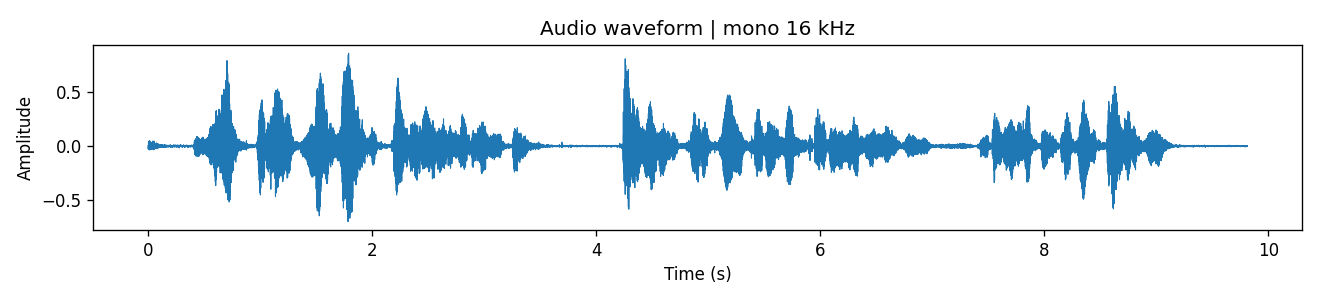

In [11]:
# 원본 함수로 WAV 읽기·모노화·16 kHz 변환을 실제 실행함.
show_preprocessing_source("load_audio")
waveform_16k = frozen_preprocessing.load_audio(MEDIA_AUDIO_PATH)
np.testing.assert_array_equal(waveform_16k, preprocessing_arrays["audio_waveform_16k"])
processor_config = preprocessing_record["effective_audio_processor"]
assert processor_config["sampling_rate"] == 16000
assert processor_config["do_normalize"] is False
processor_input = waveform_16k[None, :].copy()
np.testing.assert_array_equal(processor_input, preprocessing_arrays["audio_processor_input"])
chunk_samples = max(400, round(preprocessing_example["audio"]["chunk_seconds"] * 16000))
chunk_rows = []
for i, start in enumerate(range(0, processor_input.shape[1], chunk_samples)):
    end = min(start + chunk_samples, processor_input.shape[1])
    piece = processor_input[:, start:end]
    if piece.shape[1] < 400:
        piece = np.pad(piece, ((0, 0), (0, 400 - piece.shape[1])))
    assert [start, end] == preprocessing_arrays["audio_chunk_spans"][i].tolist()
    assert piece.shape[1] == preprocessing_arrays["audio_chunk_input_lengths"][i]
    chunk_rows.append({"조각": i + 1, "시작 샘플": start, "종료 샘플": end,
                       "모델 입력 샘플 수": piece.shape[1],
                       "숨은 상태 프레임 수": int(preprocessing_arrays["audio_chunk_hidden_counts"][i])})
show_table([{"표본화 주파수": 16000, "채널 수": 1, "dtype": str(waveform_16k.dtype),
             "샘플 수": len(waveform_16k), "길이(초)": len(waveform_16k) / 16000,
             "processor do_normalize": processor_config["do_normalize"]}])
show_table(chunk_rows)
fig, ax = plt.subplots(figsize=(11, 2.5))
ax.plot(np.arange(len(waveform_16k)) / 16000, waveform_16k, linewidth=.65)
ax.set(xlabel="Time (s)", ylabel="Amplitude", title="Audio waveform | mono 16 kHz")
fig.tight_layout()
waveform_png = io.BytesIO()
fig.savefig(waveform_png, format="png", dpi=120)
display(Image(data=waveform_png.getvalue()))
plt.close(fig)


## 2-9. 운율 전처리와 16차원 통계 확인

프레임 길이 1024샘플(64 ms), 이동 간격 320샘플(20 ms)로 STFT를 계산함.
YIN의 기본주파수 범위는 50~500 Hz임. RMS와 스펙트럼 평탄도로 유성 프레임을 판정함.
RMS 임계값은 `max(10^(-45/20), 최대 RMS × 10^(-35/20))`, 평탄도 기준은 0.25임.
로그 RMS는 최솟값 1e-7을 적용함. 길이·음량·피치·유성 비율·영교차율·주파수 분포를 16개 값으로 집계함.

**실행 내용:** 원본 전처리 함수 전체를 표시하고 선택 음성의 운율을 실제로 계산함.
원본 샘플에서 계산한 값과 준비 단계에서 저장한 값이 허용 오차 내에서 일치하는지 확인함.


In [12]:
# 스펙트럼·피치 계산부터 16개 통계 집계까지 원래 함수를 실행함.
show_preprocessing_source("extract_prosody")
live_prosody = frozen_preprocessing.extract_prosody(waveform_16k)
np.testing.assert_allclose(live_prosody, preprocessing_arrays["prosody_feature"], atol=1e-4, rtol=1e-4)
show_table([{"순서": i + 1, "운율 특징": name, "실제 계산값": float(live_prosody[i]),
             "준비 단계 값": float(preprocessing_arrays["prosody_feature"][i])}
            for i, name in enumerate(frozen_preprocessing.PROSODY_NAMES)])
print("STFT 배열:", preprocessing_arrays["prosody_stft_magnitude"].shape,
      "| 전체 프레임:", len(preprocessing_arrays["prosody_f0"]),
      "| 유성 프레임:", int(preprocessing_arrays["prosody_voiced"].sum()))


def extract_prosody(waveform):
    """16 raw statistics, no corpus/speaker normalization or label information.

    Natural-log RMS has floor 1e-7. YIN uses 50..500Hz, 64ms frames/20ms hop.
    Voicing is an explicit energy/flatness proxy, not calibrated pitch confidence:
    RMS > max(-45dBFS, peak RMS-35dB) and spectral flatness < .25. Quiet is
    the complement of the energy gate. F0 deltas require adjacent voiced frames.
    Empty voiced sets map F0 statistics to zero; voiced_fraction exposes this.
    """
    import librosa
    import numpy as np
    y = np.pad(waveform, (0, max(0, 1024 - len(waveform))))
    spectrum = abs(librosa.stft(y, n_fft=1024, hop_length=320))
    rms = librosa.feature.rms(S=spectrum, frame_length=1024)[0]
    flatness = librosa.feature.spectral_flatness(S=spectrum)[0]
    energy_gate = rms > max(10 ** (-45 / 20), float(rms.max()) * 10 ** (-35 / 20))
    f0 = librosa.yin(y, fmin=50, fmax=500, sr=16000, frame_length=1024, hop_length=320)
    voiced = energy_gate & (flatness < .25) & np.isfinite(f0)
    log_f0 = np.log(np.maximum(f0, 1))
    selected = log_f0[voiced]
    adjacent = voiced[:-1] & voiced[1:]
    f0_delta = np.abs(np.diff(log_f0))[adjacent]
    log_rms = np.log(np.maximum(rms, 1e-7))
    zcr = librosa.feature.zero_crossing_rate(y, frame_length=1024, hop_length=320)[0]
    centroid = librosa.feature.spectral_centroid(S=spectrum, sr=16000)[0]
    rolloff = librosa.feature.spectral_rolloff(S=spectrum, sr=16000, roll_percent=.85)[0]
    values = [np.log1p(len(waveform) / 16000), log_rms.mean(), log_rms.std(),
              np.abs(np.diff(log_rms)).mean() if len(log_rms) > 1 else 0,
              selected.mean() if len(selected) else 0, selected.std() if len(selected) else 0,
              np.diff(np.percentile(selected, [25, 75]))[0] if len(selected) else 0,
              f0_delta.mean() if len(f0_delta) else 0, voiced.mean(), zcr.mean(), zcr.std(),
              centroid.mean(), centroid.std(), rolloff.mean(), flatness.mean(), (~energy_gate).mean()]
    return np.asarray(values, dtype=np.float32)

/home/neuroai-server05/PycharmProjects/ICASSP_Hetero/.venv-emotionheart/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


순서,운율 특징,실제 계산값,준비 단계 값
1,log1p_duration_seconds,2.380471706390381,2.380471706390381
2,log_rms_mean,-3.9551548957824707,-3.95515513420105
3,log_rms_std,1.3509951829910278,1.3509953022003174
4,log_rms_mean_absolute_delta,0.2773929238319397,0.2773929238319397
5,voiced_log_f0_mean,5.511155128479004,5.511155128479004
6,voiced_log_f0_std,0.3746923506259918,0.3746923506259918
7,voiced_log_f0_iqr,0.3701162338256836,0.3701162338256836
8,voiced_log_f0_mean_absolute_delta,0.11014606803655624,0.11014606803655624
9,voiced_fraction,0.7739307284355164,0.7739307284355164
10,zcr_mean,0.10732044279575348,0.10732044279575348


STFT 배열: (513, 491) | 전체 프레임: 491 | 유성 프레임: 380


## 2-10. 텍스트 토큰화와 RoBERTa 입력 확인

원본 전사 문장을 고정된 RoBERTa 토크나이저로 변환함.
최대 510개 일반 토큰마다 시작·종료 특수 토큰을 붙여 모델에 전달함.
RoBERTa 마지막 층의 출력 중 특수 토큰을 제외한 벡터를 모아 평균함.

**실행 내용:** 패키지에 준비한 원래 토크나이저 설정으로 텍스트를 실제 토큰화함.
원문·토큰 문자열·토큰 ID·특수 토큰을 포함한 모델 입력 순서를 표시함.


In [13]:
# 로컬 tokenizer.json을 읽어 원문을 실제 토큰화함. 네트워크 연결 없이 실행됨.
from tokenizers import Tokenizer
tokenizer_path = PREPROCESSING_ROOT / preprocessing_record["portable_tokenizer"]["path"]
assert demo.sha(tokenizer_path) == preprocessing_record["portable_tokenizer"]["sha256"]
tokenizer = Tokenizer.from_file(str(tokenizer_path))
encoded = tokenizer.encode(MEDIA_EXAMPLE["text"], add_special_tokens=False)
token_ids = encoded.ids
np.testing.assert_array_equal(token_ids, preprocessing_arrays["text_token_ids"])
text_input_ids, special_mask = [], []
for start in range(0, len(token_ids), 510):
    piece = token_ids[start:start + 510]
    text_input_ids.extend([tokenizer.token_to_id("<s>"), *piece, tokenizer.token_to_id("</s>")])
    special_mask.extend([True, *([False] * len(piece)), True])
np.testing.assert_array_equal(text_input_ids, preprocessing_arrays["text_input_ids"])
np.testing.assert_array_equal(special_mask, preprocessing_arrays["text_special_tokens_mask"])
print("원본 전사:", MEDIA_EXAMPLE["text"])
show_table([{"순서": i + 1, "토큰 ID": token, "토큰 문자열": encoded.tokens[i],
             "해당 토큰 해독": preprocessing_example["text_processing"]["decoded_tokens"][i]}
            for i, token in enumerate(token_ids)])
show_table([{"모델 입력 ID": text_input_ids, "일반 토큰 수": len(token_ids),
             "마지막 층 배열": list(preprocessing_arrays["text_hidden_states"].shape)}])


원본 전사: Yes but my wallet was stolen, I don't have anything.  I don't have any credit cards, I don't have my ID.  Don't you have things on file here?


순서,토큰 ID,토큰 문자열,해당 토큰 해독
1,9904,Yes,Yes
2,53,Ġbut,but
3,127,Ġmy,my
4,14952,Ġwallet,wallet
5,21,Ġwas,was
6,3579,Ġstolen,stolen
7,6,",",","
8,38,ĠI,I
9,218,Ġdon,don
10,75,'t,'t


모델 입력 ID,일반 토큰 수,마지막 층 배열
"[0, 9904, 53, 127, 14952, 21, 3579, 6, 38, 218, 75, 33, 932, 4, 1437, 38, 218, 75, 33, 143, 1361, 3591, 6, 38, 218, 75, 33, 127, 4576, 4, 1437, 1599, 75, 47, 33, 383, 15, 2870, 259, 116, 2]",39,"[39, 768]"


## 2-11. 영상 프레임 선택·크기 조절·정규화 확인

발화 시작·종료 구간을 3등분한 각 구간의 중앙 시각에서 프레임을 선택함.
`floor(시각 × FPS)`로 프레임 번호를 구하며 전체 프레임을 RGB로 변환함.
짧은 변을 256으로 조절하고 중앙 224×224를 선택함. 0~1로 변환한 RGB 값에
평균 `[0.485, 0.456, 0.406]`, 표준편차 `[0.229, 0.224, 0.225]`를 적용함.

### 함수 `prepare_rgb_frame`
- **기능:** 원본 RGB 프레임의 크기 조절·중앙 자르기·채널별 정규화를 실제 실행함.
- **입력:** `rgb` — uint8 원본 프레임, `config` — 저장된 ResNet18 변환 설정.
- **반환값:** `[3, 224, 224]` float32 입력 텐서.

**확인:** 원본 영상에서 보존한 3프레임과 변환 결과를 나란히 표시함.
현장 계산 텐서가 준비 단계의 실제 ResNet18 입력과 일치해야 함.


def visual_sampling(start, end, fps, frame_count):
    """Sample only the observed annotation/video intersection, without time shifts.

    Some source AVIs end during the final annotated utterance. Preserve this
    coverage loss explicitly; never replace missing frames with other times.
    """
    import numpy as np
    if not np.isfinite([start, end, fps]).all() or end <= start or fps <= 0 or frame_count <= 0:
        raise ValueError("Invalid video sampling interval or metadata")
    observed_start, observed_end = max(0.0, start), min(end, frame_count / fps)
    if observed_end <= observed_start:
        raise ValueError("Annotation has no observed video overlap")
    times = observed_start + (np.arange(3) + .5) * (observed_end - observed_start) / 3
    indices = np.floor(times * fps).astype(int)
    if np.any(indices < 0) or np.any(indices >= frame_count):
        raise ValueError("Sampling did not resolve to available video frames")
    return {"original_interval": [start, end],
            "observed_interval": [observed_start, observed_end],
            "visual_coverage_fraction": (observed_end - observed_start) / (end - start),
            "partial_clip": observed_start != start or observed_end != end,
            "sample_times": times.tolist(), "frame_indices": indices.tolist(),
            "frame_times": (indices / fps).tolist(),
            "fps": fps, "frame_count": frame_count, "speaker_crop": False}

프레임,선택 시각(초),프레임 번호,실제 프레임 시각(초)
1,74.08500000000001,2220,74.07407407407408
2,77.355,2318,77.34401067734402
3,80.625,2416,80.61394728061396


순서,원본 전체 프레임,224×224 입력의 색상 복원
프레임 1,,
프레임 2,,
프레임 3,,

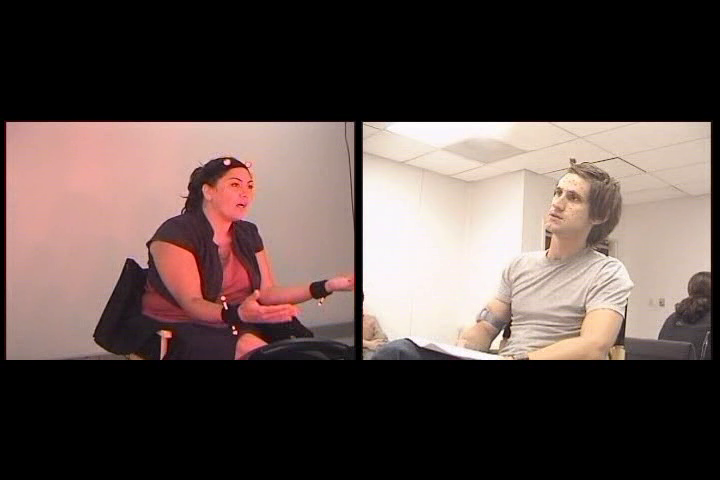
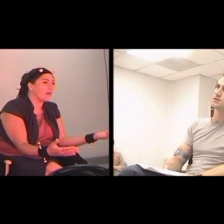
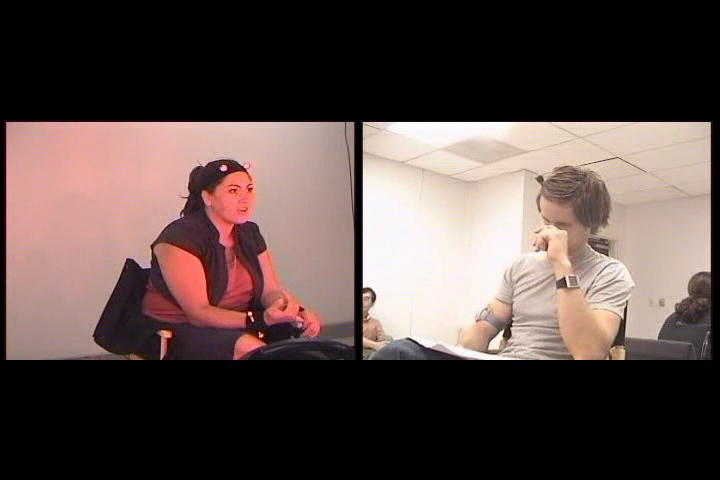
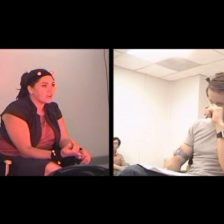
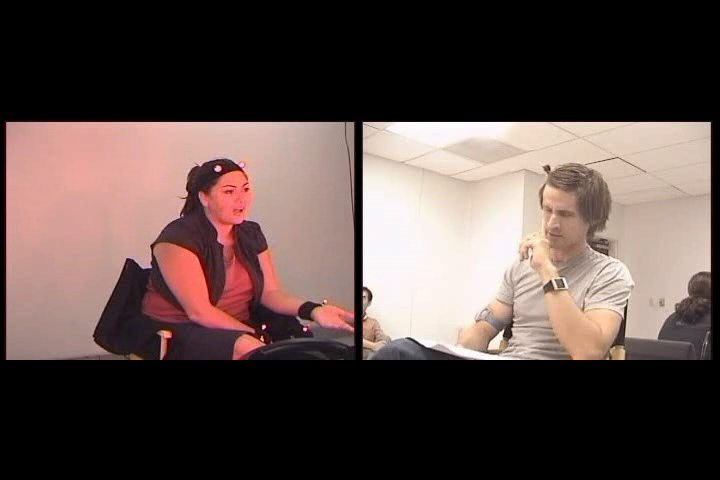
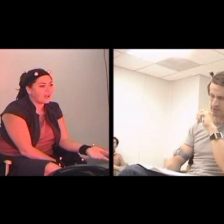

최종 입력 배열,평균,표준편차,저장된 입력과 비교
"[3, 3, 224, 224]","[0.485, 0.456, 0.406]","[0.229, 0.224, 0.225]",통과


In [14]:
# 원래 프레임 선택 함수와 선택된 세 시각·프레임 번호를 확인함.
show_preprocessing_source("visual_sampling")
visual_info = preprocessing_example["visual"]
sampling = frozen_preprocessing.visual_sampling(MEDIA_EXAMPLE["start"], MEDIA_EXAMPLE["end"],
                                                visual_info["fps"], visual_info["frame_count"])
assert sampling == {k: visual_info[k] for k in sampling}
show_table([{"프레임": i + 1, "선택 시각(초)": sampling["sample_times"][i],
             "프레임 번호": frame, "실제 프레임 시각(초)": sampling["frame_times"][i]}
            for i, frame in enumerate(sampling["frame_indices"])])

def prepare_rgb_frame(rgb, config):
    # torchvision의 uint8 텐서 resize와 같은 bilinear·antialias·반올림 순서를 적용함.
    tensor = torch.from_numpy(rgb.copy()).permute(2, 0, 1)
    height, width = tensor.shape[-2:]
    short = config["resize_size"][0]
    resized_size = [short, int(short * width / height)] if height <= width else [int(short * height / width), short]
    resized = torch.nn.functional.interpolate(tensor[None].float(), size=resized_size,
                 mode="bilinear", align_corners=False, antialias=config["antialias"])[0]
    resized = resized.round().clamp(0, 255).to(torch.uint8)
    crop = config["crop_size"][0]
    top, left = round((resized_size[0] - crop) / 2), round((resized_size[1] - crop) / 2)
    values = resized[:, top:top + crop, left:left + crop].float() / 255
    mean = torch.tensor(config["mean"], dtype=torch.float32)[:, None, None]
    std = torch.tensor(config["std"], dtype=torch.float32)[:, None, None]
    return (values - mean) / std

def png_html(rgb):
    stream = io.BytesIO()
    PILImage.fromarray(rgb).save(stream, format="PNG")
    return '<img style="max-width:100%;height:auto" src="data:image/png;base64,' + base64.b64encode(stream.getvalue()).decode() + '">'

config = preprocessing_record["effective_visual_transform"]
assert config["interpolation"] == "InterpolationMode.BILINEAR"
live_visual_inputs, panels = [], []
for i, frame in enumerate(visual_info["frames"]):
    frame_path = PREPROCESSING_ROOT / frame["path"]
    assert frame_path.is_relative_to(PREPROCESSING_ROOT) and demo.sha(frame_path) == frame["sha256"]
    rgb = np.asarray(PILImage.open(frame_path).convert("RGB"))
    transformed = prepare_rgb_frame(rgb, config)
    live_visual_inputs.append(transformed)
    np.testing.assert_allclose(transformed.numpy(), preprocessing_arrays["visual_inputs_224"][i], atol=1e-6, rtol=0)
    restored = transformed.numpy() * np.asarray(config["std"], dtype=np.float32)[:, None, None]
    restored += np.asarray(config["mean"], dtype=np.float32)[:, None, None]
    cropped_rgb = np.clip(np.round(restored.transpose(1, 2, 0) * 255), 0, 255).astype(np.uint8)
    panels.append('<tr><td>프레임 ' + str(i + 1) + '</td><td>' + png_html(rgb) + '</td><td>' + png_html(cropped_rgb) + '</td></tr>')
display(HTML('<table><tr><th>순서</th><th>원본 전체 프레임</th><th>224×224 입력의 색상 복원</th></tr>' + ''.join(panels) + '</table>'))
show_table([{"최종 입력 배열": list(torch.stack(live_visual_inputs).shape),
             "평균": config["mean"], "표준편차": config["std"], "저장된 입력과 비교": "통과"}])


## 2-12. 고정 특징 추출 코드와 최종 특징 집계 확인

아래 원본 `make_extractor`에 운율·WavLM·RoBERTa·ResNet18의 모델 로딩, 입력 구성, 순전파, 집계 코드가 모두 포함됨.
준비 단계에서는 같은 가중치·설정으로 이 연산을 실행해 30개 발화의 중간 출력을 보존함.
`prepare_preprocessing.py`에는 해당 준비 작업의 전체 실행 코드와 비교 검사가 들어 있음.

**현장 실행:** WavLM 숨은 상태의 평균·모집단 표준편차, RoBERTa 일반 토큰 평균,
ResNet18 3프레임 평균을 직접 계산함. 운율은 2-9절에서 직접 계산한 값을 사용함.
기존 특징 캐시와 모달리티별 차이를 확인한 뒤 4단계에서 학습 통계 정규화와 감정 모델 추론을 이어서 실행함.

**확인:** 최종 크기 1536·16·768·512, `atol=1e-4`, `rtol=1e-4`의 기존 특징 비교를 통과해야 함.


In [15]:
# 원본 고정 특징 추출기의 전체 코드를 표시함.
show_preprocessing_source("make_extractor")
audio_states = torch.from_numpy(preprocessing_arrays["audio_hidden_states"])
text_states = torch.from_numpy(preprocessing_arrays["text_hidden_states"])
visual_states = torch.from_numpy(preprocessing_arrays["visual_frame_features"])
reconstructed_features = {
    "audio": torch.cat([audio_states.mean(0), audio_states.std(0, unbiased=False)]).numpy(),
    "prosody": live_prosody,
    "text": text_states.mean(0).numpy(),
    "visual": visual_states.mean(0).numpy(),
}
with np.load(ROOT / "data/features/dialogues" / f"{EXAMPLE_DIALOGUE}.npz", allow_pickle=False) as cache:
    cache_index = cache["ids"].tolist().index(MEDIA_EXAMPLE["id"])
    preprocessing_comparison = []
    for name, expected_dim in demo.DIMS.items():
        actual, expected = reconstructed_features[name], cache[name][cache_index]
        assert actual.shape == (expected_dim,)
        np.testing.assert_allclose(actual, expected, atol=1e-4, rtol=1e-4)
        preprocessing_comparison.append({"입력": name, "발화 ID": MEDIA_EXAMPLE["id"],
            "차원": expected_dim, "최대 절대 차이": float(np.max(np.abs(actual.astype(np.float64) - expected))),
            "첫 5개 값": actual[:5].round(5).tolist(), "검사": "통과"})
show_table(preprocessing_comparison)


def make_extractor(modality, device, chunk_seconds):
    """Return a local callable and the exact public-model/library provenance."""
    import numpy as np
    packages = ["numpy", "librosa", "soundfile"] if modality == "prosody" else ["numpy", "torch"]
    if modality in ("audio", "text"):
        packages += ["transformers", "huggingface-hub"]
    if modality == "visual":
        packages += ["torchvision", "opencv-python-headless"]
    info = {"modality": modality, "implementation": "iemocap-local-features-v1",
            "packages": {p: importlib.metadata.version(p) for p in packages}}
    if modality == "prosody":
        info.update({"names": PROSODY_NAMES, "sample_rate": 16000,
                     "frame_samples": 1024, "hop_samples": 320,
                     "voicing": "YIN 50..500Hz; energy>-45dBFS and peak-35dB; flatness<0.25"})
        def prosody(utterance):
            y = load_audio(utterance["audio_path"])
            return extract_prosody(y), {"duration_seconds": len(y) / 16000, "truncated": False}
        return prosody, info
    import torch
    if modality == "audio":
        from transformers import AutoFeatureExtractor, AutoModel
        name = "microsoft/wavlm-base-plus"
        processor = AutoFeatureExtractor.from_pretrained(name)
        model = AutoModel.from_pretrained(name).eval().to(device)
        info.update({"model": name, "revision": model.config._commit_hash,
                     "sample_rate": 16000, "chunk_seconds": chunk_seconds,
                     "pooling": "all final hidden frames mean+population std; no overlap",
                     "waveform_normalization": "whole utterance before chunking"})
        def audio(utterance):
            y = load_audio(utterance["audio_path"])
            inputs = processor(y, sampling_rate=16000, return_tensors="pt").input_values
            length = max(400, round(chunk_seconds * 16000))
            frames = []
            with torch.inference_mode():
                for start in range(0, inputs.shape[1], length):
                    piece = inputs[:, start:start + length]
                    if piece.shape[1] < 400:
                        piece = torch.nn.functional.pad(piece, (0, 400 - piece.shape[1]))
                    frames.append(model(piece.to(device)).last_hidden_state[0].float().cpu())
            states = torch.cat(frames)
            feature = torch.cat([states.mean(0), states.std(0, unbiased=False)]).numpy()
            return feature, {"duration_seconds": len(y) / 16000, "chunks": len(frames),
                             "hidden_frames": len(states), "truncated": False}
        return audio, info
    if modality == "text":
        from transformers import AutoModel, AutoTokenizer
        name = "FacebookAI/roberta-base"
        tokenizer = AutoTokenizer.from_pretrained(name)
        model = AutoModel.from_pretrained(name).eval().to(device)
        info.update({"model": name, "revision": model.config._commit_hash,
                     "pooling": "mean of nonspecial tokens across complete 510-token chunks"})
        def text(utterance):
            tokens = tokenizer.encode(utterance["text"], add_special_tokens=False)
            if not tokens:
                raise ValueError(f"No text tokens: {utterance['id']}")
            states = []
            with torch.inference_mode():
                for start in range(0, len(tokens), 510):
                    ids = tokenizer.build_inputs_with_special_tokens(tokens[start:start + 510])
                    hidden = model(input_ids=torch.tensor([ids], device=device)).last_hidden_state[0]
                    states.append(hidden[1:-1].float().cpu())
            return torch.cat(states).mean(0).numpy(), {"tokens": len(tokens), "truncated": False}
        return text, info
    import cv2
    from torchvision.models import ResNet18_Weights, resnet18
    weights = ResNet18_Weights.IMAGENET1K_V1
    model = resnet18(weights=weights)
    model.fc = torch.nn.Identity()
    model = model.eval().to(de

입력,발화 ID,차원,최대 절대 차이,첫 5개 값,검사
audio,Ses01F_impro01_F011,1536,0.0,"[-0.05587000027298927, 0.026149999350309372, -0.0589900016784668, 0.02865999937057495, -0.012760000303387642]",통과
prosody,Ses01F_impro01_F011,16,2.384185791015625e-07,"[2.380470037460327, -3.955159902572632, 1.3509999513626099, 0.2773900032043457, 5.511159896850586]",통과
text,Ses01F_impro01_F011,768,0.0,"[-0.042750000953674316, 0.11151999980211258, -0.029069999232888222, -0.100040003657341, -0.15338000655174255]",통과
visual,Ses01F_impro01_F011,512,2.384185791015625e-07,"[0.472460001707077, 0.47477999329566956, 0.13662999868392944, 0.6541399955749512, 0.3654400110244751]",통과


# 3. 5겹 교차검증 평가 조건 확인
## 3-1. 학습·개발·시험 세션 구분

k번 폴드는 k번 세션을 시험, 다음 순환 세션을 개발, 나머지 3개 세션을 학습에 사용했음.
개발 세션은 가중치 선택에, 시험 세션은 현장 추론과 채점에 사용함.

**실행 내용:** 기존에 확정한 평가 설정에서 분리표를 읽고 세 집합이 겹치지 않는지 확인함.

**k번 세션은 해당 세션을 학습·개발에서 제외한 k번 폴드 모델로 평가함.**
OOF(전체 폴드의 시험 예측) 결과에서 각 발화의 예측은 과제별로 한 번씩 포함되며, 과제별 유효 마스크를 적용해 채점함.


In [16]:
# 3-1. 폴드마다 실제 대화 ID를 세션 번호로 바꾸어 학습·개발·시험 분리표를 만듦.
# 모든 분리 조건은 1-3절에서 검사했고, 여기서는 시험 세션이 겹치지 않는지 다시 확인함.
split_rows = []
for fold in protocols["classification"]["folds"]:
    groups = {role: sorted({original[did]["session"] for did in fold[role]}) for role in ("train", "dev", "test")}
    # 시험 자료가 해당 모델의 학습이나 개발에 들어가지 않았는지 검사함.
    assert not (set(groups["train"]) & set(groups["test"]))
    assert not (set(groups["dev"]) & set(groups["test"]))
    split_rows.append({"Fold": fold["fold"], "학습 세션": groups["train"], "개발 세션": groups["dev"],
                       "시험 세션": groups["test"], "시험 대화 수": len(fold["test"])})
show_table(split_rows)


Fold,학습 세션,개발 세션,시험 세션,시험 대화 수
1,"[3, 4, 5]",[2],[1],28
2,"[1, 4, 5]",[3],[2],30
3,"[1, 2, 5]",[4],[3],32
4,"[1, 2, 3]",[5],[4],30
5,"[2, 3, 4]",[1],[5],31


## 3-2. 학습 완료 가중치와 선택 기록 확인

각 과제의 폴드별 `best.pt`를 사용함. 분류는 개발 자료의 가중 F1, 회귀는 개발 자료의 평균 CCC가 처음으로 최댓값을 기록한 에포크의 가중치임.
50에포크 학습과 모델 선택은 이미 완료되어 있음. 아래 코드는 기록만 읽음.

**확인:** 분류 5개·회귀 5개, 총 10개 행과 선택 에포크가 출력됨. SHA256은 읽기 쉽도록 앞 16자리만 표시하며 사전 검사에서는 전체 해시를 대조했음.


In [17]:
# 3-2. 학습 완료 당시 확정한 모델 선택 기록을 읽어 표로 보여줌.
# 기존에 확정한 가중치를 사용함. 해시는 읽기 쉽도록 앞 16자리만 표시함.
weight_rows = []
for task in demo.TASKS:
    for fold in range(1, 6):
        # 분류는 개발 가중 F1, 회귀는 개발 평균 CCC를 기준으로 확정한 기록임.
        lock = demo.read(ROOT / "evidence" / task / f"fold{fold}/selection.json")
        weight_rows.append({"과제": task, "Fold": fold, "선택 epoch": lock["best_epoch"],
                            "완료 epoch": lock["epochs_completed"], "개발 선택 점수": round(lock["dev_score"], 6),
                            "가중치 SHA256 앞 16자리": lock["checkpoint_sha256"][:16]})
show_table(weight_rows)


과제,Fold,선택 epoch,완료 epoch,개발 선택 점수,가중치 SHA256 앞 16자리
classification,1,47,50,0.824563,3f542a814a8ab7ab
classification,2,40,50,0.763322,02fd60e0c4360056
classification,3,25,50,0.804319,3c7b63e65618b61d
classification,4,25,50,0.800509,2305e39b4463e855
classification,5,26,50,0.742271,e2b10471d879a80e
va,1,24,50,0.738636,e5bd6dd0dab51f48
va,2,33,50,0.693093,20a18da37c489467
va,3,39,50,0.708274,c3d5a61e0285b04d
va,4,31,50,0.735015,abd6fd7a197d8f0b
va,5,23,50,0.734993,7e52100282134ab1


# 4. 예시 대화로 추론 과정 확인
## 4-1. 학습에 사용하지 않은 시험 특징 불러오기

### 함수 `load_test_features`
- **기능:** 지정한 폴드의 시험 대화인지 확인하고 그 대화의 특징과 구조 정보만 읽음.
- **입력 인자:** `dialogue_id` — 대화 ID, `fold_number` — 1~5의 가중치 번호.
- **반환값:** `features` — 음성·운율·텍스트·영상 배열, `structure` — 화자·순서·시간, `ids` — 발화 ID 배열.

**확인:** 모든 특징의 첫 번째 차원(발화 수)이 같고, 정답 라벨이 입력 딕셔너리에 없음.


In [18]:
# 4-1. 시험 대화의 특징과 구조 정보를 불러오는 함수를 정의함.
# 입력: dialogue_id(대화 ID), fold_number(해당 모델의 폴드 번호).
# 반환: features(특징 배열), structure(화자·순서·시간), ids(발화 ID 배열).
def load_test_features(dialogue_id, fold_number):
    split = protocols["classification"]["folds"][fold_number - 1]
    # k번 세션의 발화는 그 세션을 학습·개발에서 제외한 k번 모델에만 전달함.
    assert dialogue_id in split["test"]
    assert dialogue_id not in split["train"] + split["dev"]
    with np.load(ROOT / "data/features/dialogues" / f"{dialogue_id}.npz", allow_pickle=False) as data:
        # 모델 입력용 특징과 구조 정보를 복사함.
        features = {name: data[name].copy() for name in demo.DIMS}
        structure = {name: data[name].copy() for name in ("speaker", "order", "times")}
        ids = data["ids"].copy()
    expected = [u["id"] for u in descriptor_index["classification"][dialogue_id]["utterances"]]
    # 특징의 행 순서와 정답 정의의 발화 순서가 정확히 일치해야 함.
    assert ids.tolist() == expected
    return features, structure, ids

features, structure, example_ids = load_test_features(EXAMPLE_DIALOGUE, EXAMPLE_FOLD)
show_table([{"입력": name, "배열 크기": list(value.shape), "dtype": str(value.dtype)} for name, value in features.items()])


입력,배열 크기,dtype
audio,"[30, 1536]",float32
prosody,"[30, 16]",float32
text,"[30, 768]",float32
visual,"[30, 512]",float32


## 4-2. 저장된 모델 가중치 불러오기

### 함수 `load_frozen_model`
- **기능:** 해당 과제·폴드의 모델 저장 파일을 읽고 같은 구조의 모델에 가중치를 로딩함.
- **입력 인자:** `task` — `classification` 또는 `va`, `fold_number` — 대응 시험 세션 번호.
- **반환값:** `model` — 평가 모드 모델, `normalizer` — 해당 학습 폴드에서 계산해 저장한 평균·표준편차.

`model.eval()`은 드롭아웃을 평가 모드로 전환하고 `requires_grad_(False)`는 기울기 계산을 끔.
모델 생성 직후 `load_state_dict(..., strict=True)`로 학습 완료 가중치를 모두 로딩함.

**확인:** 분류와 회귀 모델이 로딩되고 각각 `training=False`가 출력됨.


In [19]:
# 4-2. 과제와 시험 폴드에 맞는 학습 완료 모델을 불러옴.
# 입력: task는 classification 또는 va, fold_number는 1~5.
# 반환: 평가 모드의 모델과 이 모델의 학습 자료에서 계산해 저장한 정규화 통계.
def load_frozen_model(task, fold_number):
    saved = demo.load_checkpoint(task, fold_number)
    assert saved["task"] == task and saved["protocol_hash"] == demo.digest(protocols[task])
    split = protocols[task]["folds"][fold_number - 1]
    # 가중치가 현재 평가 설정과 해당 폴드에 속하는지 식별값으로 확인함.
    assert saved["identity"] == demo.digest(dict(protocol=protocols[task], fold=split))
    outputs = 7 if task == "classification" else 2
    model = demo.InductiveGraph(demo.DIMS, outputs, variant="multi_graph", **protocols[task]["graph"]).to(DEVICE)
    # 학습 때와 같은 구조를 만든 뒤 모든 가중치를 엄격히 로딩함.
    model.load_state_dict(saved["model"], strict=True)
    # 드롭아웃 등을 평가 모드로 바꾸고 파라미터의 기울기 계산도 끔.
    model.eval().requires_grad_(False)
    return model, saved["normalizer"]

# 분류와 회귀는 별도로 학습했으므로 각 모델의 가중치와 정규화 통계를 각각 가져옴.
classification_model, classification_normalizer = load_frozen_model("classification", EXAMPLE_FOLD)
va_model, va_normalizer = load_frozen_model("va", EXAMPLE_FOLD)
print("classification training:", classification_model.training)
print("va training:", va_model.training)


classification training: False
va training: False


## 4-3. 학습 때 저장한 통계로 입력 정규화

### 함수 `prepare_inputs`
- **기능:** 각 특징에 `(x − 학습 자료의 평균) / 학습 자료의 표준편차`를 적용하고 PyTorch 텐서로 변환함.
- **입력 인자:** `features`, `structure` — 4-1의 입력, `normalizer` — 4-2에서 읽은 해당 모델의 통계.
- **반환값:** `batch` — 모델에 전달할 특징·화자·순서·시간만 포함한 딕셔너리.

각 모델의 학습 자료에서 계산해 저장한 평균·표준편차를 적용함. 정답은 발화별 예측 비교와 채점에 사용함.

**실행 내용:** 선택 발화의 모달리티별 첫 3차원에 대해 원래 값·학습 평균·학습 표준편차·정규화 값을 나란히 표시함. 분류와 회귀의 저장 통계를 각각 확인함.


In [20]:
# 4-3. 모델별로 저장된 평균·표준편차를 적용해 입력 텐서를 만듦.
# 입력: features(원래 특징), structure(구조 정보), normalizer(저장 통계).
# 반환: 모델 입력만 담은 batch 딕셔너리. 학습 때 저장한 정규화 통계를 재사용함.
def prepare_inputs(features, structure, normalizer):
    # 특징은 (값 - 학습 평균) / 학습 표준편차로 변환하고 float32 텐서에 담음.
    batch = {name: torch.as_tensor((features[name] - normalizer[name]["mean"]) / normalizer[name]["std"],
                                   dtype=torch.float32, device=DEVICE) for name in demo.DIMS}
    # 화자·순서·시간은 특징 정규화 대상이 아니므로 원래 배열 자료형으로 전달함.
    batch.update({name: torch.as_tensor(value, device=DEVICE) for name, value in structure.items()})
    # 정답이나 다른 필드가 모델 입력에 섞이지 않았는지 입력 키를 검사함.
    assert set(batch) == set(demo.DIMS) | {"speaker", "order", "times"}
    return batch

classification_inputs = prepare_inputs(features, structure, classification_normalizer)
va_inputs = prepare_inputs(features, structure, va_normalizer)
print("모델 입력 필드:", sorted(classification_inputs))

# 선택 발화의 정규화 전후 값을 각 과제의 실제 저장 통계와 함께 확인함.
selected_index = example_ids.tolist().index(MEDIA_EXAMPLE["id"])
normalization_rows = []
for task, normalizer, batch in [("분류", classification_normalizer, classification_inputs),
                                 ("회귀", va_normalizer, va_inputs)]:
    for name in demo.DIMS:
        for dimension in range(3):
            normalization_rows.append({"과제": task, "입력": name, "차원": dimension,
                "원래 특징": float(features[name][selected_index, dimension]),
                "학습 평균": float(normalizer[name]["mean"][dimension]),
                "학습 표준편차": float(normalizer[name]["std"][dimension]),
                "정규화 값": float(batch[name][selected_index, dimension].cpu())})
show_table(normalization_rows)


모델 입력 필드: ['audio', 'order', 'prosody', 'speaker', 'text', 'times', 'visual']


과제,입력,차원,원래 특징,학습 평균,학습 표준편차,정규화 값
분류,audio,0,-0.05587184429168701,-0.010657700709998608,0.03250914067029953,-1.3908132314682007
분류,audio,1,0.02614590711891651,0.04083780199289322,0.020639706403017044,-0.711826741695404
분류,audio,2,-0.05898704379796982,-0.03520188853144646,0.027343284338712692,-0.8698719143867493
분류,prosody,0,2.380471706390381,1.566755771636963,0.47403401136398315,1.716577172279358
분류,prosody,1,-3.95515513420105,-5.670141220092773,0.8252633810043335,2.0781075954437256
분류,prosody,2,1.3509953022003174,1.0686577558517456,0.26445427536964417,1.067623257637024
분류,text,0,-0.042751189321279526,-0.014097191393375397,0.05167249217629433,-0.5545309782028198
분류,text,1,0.11152099817991257,0.04887237399816513,0.07899635285139084,0.7930571436882019
분류,text,2,-0.029069606214761734,0.037197209894657135,0.05396728217601776,-1.2279072999954224
분류,visual,0,0.47245869040489197,0.691766083240509,0.4232296943664551,-0.5181758403778076


## 4-4. 이산·연속 감정 실제 추론

### 함수 `predict_dialogue`
- **기능:** `model(batch)`로 대화 전체를 추론함.
- **입력 인자:** `model` — 로딩한 모델, `batch` — 정규화 입력, `task` — 과제 구분.
- **반환값:** 분류는 `[발화 수, 7]` 확률, 회귀는 `[발화 수, 2]` V/A 예측.

분류는 소프트맥스 후 가장 큰 확률의 클래스를 선택함. 회귀는 학습 시 정의한 `3 + 2×tanh(raw)`로 1~5 범위의 값을 얻음.
`torch.inference_mode()` 안에서 평가 모드 추론을 실행함.


In [21]:
# 4-4. 준비한 특징·구조 정보를 입력해 실제 모델 순전파를 실행함.
# 입력: 평가 모드 model, 정규화한 batch, 과제 구분 task.
# 반환: 분류는 [발화 수, 7] 확률 배열, 회귀는 [발화 수, 2] 정서가·각성도 배열.
# inference_mode는 추론에 필요한 계산만 실행하도록 이 함수 안의 자동 미분 기록을 끔.
@torch.inference_mode()
def predict_dialogue(model, batch, task):
    # 그래프 모델이 대화 내부의 화자·발화 문맥과 멀티모달 특징을 사용해 출력을 계산함.
    raw = model(batch)
    # 분류는 소프트맥스로 확률을 구하고, 회귀는 학습 때와 같은 변환으로 1~5 범위를 만듦.
    prediction = raw.softmax(-1) if task == "classification" else 3 + 2 * torch.tanh(raw)
    # 추론 결과를 CPU의 NumPy 배열로 옮겨 표·파일·지표 계산에 사용함.
    result = prediction.cpu().numpy()
    assert np.isfinite(result).all()
    return result

example_class_predictions = predict_dialogue(classification_model, classification_inputs, "classification")
example_va_predictions = predict_dialogue(va_model, va_inputs, "va")
print("분류 확률 크기:", example_class_predictions.shape)
print("V/A 예측 크기:", example_va_predictions.shape)
assert np.allclose(example_class_predictions.sum(1), 1, atol=1e-6)


분류 확률 크기: (30, 7)
V/A 예측 크기: (30, 2)


## 4-5. 예시 발화의 예측과 정답 비교

**실행 내용:** 동일 발화 ID를 기준으로 원본 감정·예측 클래스, 실제 V/A·예측 V/A를 한 표에 연결함.
분류·회귀 채점 포함 여부도 함께 표시함. 화면에는 대화 순서의 첫 12개 발화를 보여줌.

**확인:** 원본 7개 감정에 해당하는 발화가 분류 채점 대상으로 표시되는지 확인함.
이 예시 표는 추론 동작 설명용이며 전체 5겹 교차검증 대표 점수는 다음 단계에서 계산함.

원본 미디어를 재생한 선택 발화의 정답·예측도 별도 표로 표시함.


In [22]:
# 4-5. 추론이 끝난 뒤 예시 대화의 정답 배열을 만들어 예측과 발화별로 연결함.
# 분류와 회귀의 채점 여부를 별도로 표시하여 채점 제외 발화도 원래 값과 함께 확인함.
example_class_targets = np.asarray([u["target"] for u in descriptor_index["classification"][EXAMPLE_DIALOGUE]["utterances"]])
example_va_targets = np.asarray([u["target"] for u in descriptor_index["va"][EXAMPLE_DIALOGUE]["utterances"]], dtype=np.float32)
example_rows = []
for i, u in enumerate(original[EXAMPLE_DIALOGUE]["utterances"]):
    emotion = u["original_emotion"]
    # 확률이 가장 큰 클래스 번호를 선택한 뒤 학습 때의 감정 이름에 대응시킴.
    prediction = int(example_class_predictions[i].argmax())
    example_rows.append({"발화 ID": u["id"], "원본 감정": CLASS_NAMES.get(emotion, emotion),
                         "예측 감정": demo.KOREAN[prediction], "분류 채점": bool(example_class_targets[i] != -100),
                         "V 정답": float(example_va_targets[i, 0]), "V 예측": round(float(example_va_predictions[i, 0]), 4),
                         "A 정답": float(example_va_targets[i, 1]), "A 예측": round(float(example_va_predictions[i, 1]), 4),
                         "V/A 채점": bool(((example_va_targets[i] >= 1) & (example_va_targets[i] <= 5)).all())})
# 대화 순서의 첫 12개를 표시함.
show_table(example_rows, limit=12)

# 원문·음성·영상·전처리를 확인한 동일 발화의 예측 결과를 연결함.
print("미디어를 확인한 발화:", MEDIA_EXAMPLE["id"], "| 원문:", MEDIA_EXAMPLE["text"])
show_table([row for row in example_rows if row["발화 ID"] == MEDIA_EXAMPLE["id"]])


발화 ID,원본 감정,예측 감정,분류 채점,V 정답,V 예측,A 정답,A 예측,V/A 채점
Ses01F_impro01_F000,중립,중립,True,2.5,3.527,2.5,2.6039,True
Ses01F_impro01_M000,fru,중립,False,2.5,3.0628,2.0,2.4182,True
Ses01F_impro01_F001,중립,중립,True,2.5,3.4228,2.5,2.4091,True
Ses01F_impro01_M001,fru,중립,False,2.5,2.2602,2.0,2.5594,True
Ses01F_impro01_F002,중립,중립,True,2.5,2.2986,2.5,2.5828,True
Ses01F_impro01_M002,fru,분노,False,2.0,2.5748,3.5,3.0847,True
Ses01F_impro01_F003,xxx,중립,False,2.5,3.1068,3.0,3.233,True
Ses01F_impro01_F004,xxx,중립,False,2.5,2.4577,3.0,2.7216,True
Ses01F_impro01_M003,fru,분노,False,2.5,2.2497,3.5,3.4361,True
Ses01F_impro01_F005,중립,분노,True,2.5,1.7898,3.5,3.6793,True


전체 30행 중 앞 12행 표시
미디어를 확인한 발화: Ses01F_impro01_F011 | 원문: Yes but my wallet was stolen, I don't have anything.  I don't have any credit cards, I don't have my ID.  Don't you have things on file here?


발화 ID,원본 감정,예측 감정,분류 채점,V 정답,V 예측,A 정답,A 예측,V/A 채점
Ses01F_impro01_F011,fru,분노,False,2.0,1.5507,3.5,4.0753,True


# 5. 전체 5겹 교차검증 평가
## 5-1. 학습 완료 10개 모델로 전체 시험 세션 추론

### 함수 `demo.run`
- **기능:** 4단계에서 살펴본 가중치 로딩·정규화·추론을 과제별 5개 폴드에 적용하고 결과를 저장함.
- **입력 인자:** `output` — 새 결과 폴더, `device` — `cpu`, `threads` — CPU 스레드 수 4.
- **반환값:** 결과 폴더 경로. 폴더에 폴드별 예측, OOF 예측, 지표, 정답 비교표, HTML 보고서를 생성함.

내부 순서는 **과제 선택 → k번 폴드 가중치 로딩 → k번 세션의 대화별 추론 → 정답 비교 → 5겹 교차검증 집계**임.
현장에서는 학습 완료 모델의 실제 `forward()`를 실행하여 각 시험 세션의 예측을 계산함.

**확인:** 분류 5줄·회귀 5줄의 진행 결과와 최종 요약이 출력됨. 실행마다 새 폴더를 생성하여 결과를 보존함.


In [23]:
# 5-1. 예시 대화에서 확인한 추론을 전체 5개 폴드에 적용함.
# 분류 5개·회귀 5개의 학습 완료 가중치로 실제 추론을 수행함.
# 실행 시각을 포함한 새 폴더를 만들어 이전 결과를 보존함.
OUT = ROOT / "results" / ("notebook_" + datetime.now(KST).strftime("%Y%m%d_%H%M%S_%f"))
demo.run(output=OUT, device=DEVICE, threads=4)
summary = demo.read(OUT / "summary.json")
# 정상 완료 상태를 확인한 뒤 해당 실행의 요약과 예측 파일을 다음 단계에서 사용함.
assert demo.read(OUT / "status.json")["status"] == "complete"
print("이번 실행 결과:", OUT)


PASS: 578 files, 10 selected checkpoints, 5 disjoint folds, source ground truth


classification fold 1/5 | test Session 1 | n=980 | accuracy=0.743878 | weighted_f1=0.741807


classification fold 2/5 | test Session 2 | n=839 | accuracy=0.812872 | weighted_f1=0.810154


classification fold 3/5 | test Session 3 | n=1031 | accuracy=0.743938 | weighted_f1=0.743726


classification fold 4/5 | test Session 4 | n=819 | accuracy=0.800977 | weighted_f1=0.797943


classification fold 5/5 | test Session 5 | n=970 | accuracy=0.781443 | weighted_f1=0.772426


... (3 outputs left out)

va             fold 4/5 | test Session 4 | n=2103 | ccc_valence=0.718724 | ccc_arousal=0.681354 | mean_ccc=0.700039


va             fold 5/5 | test Session 5 | n=2170 | ccc_valence=0.754264 | ccc_arousal=0.702463 | mean_ccc=0.728364



IEMOCAP | frozen Base | fresh inference | 5-fold mean +/- sample SD
accuracy         0.776622 +/- 0.031902
weighted_f1      0.773211 +/- 0.030954
ccc_valence      0.750615 +/- 0.037333
ccc_arousal      0.684792 +/- 0.017355
mean_ccc         0.717703 +/- 0.022541
Results: /tmp/iemocap_notebook_mwgi2tia/IEMOCAP_Official_Demo/results/notebook_20261111_170934_748212


이번 실행 결과: /tmp/iemocap_notebook_mwgi2tia/IEMOCAP_Official_Demo/results/notebook_20261111_170934_748212


## 5-2. 폴드별 성능 확인

이산 감정은 정확도·가중 F1, 연속 감정은 정서가 CCC·각성도 CCC·두 차원의 평균 CCC를 표시함.
각 폴드의 분류·회귀 채점 표본 수를 같이 확인함.

**확인:** 1~5번 폴드의 5개 행, 분류 채점 수 합계 4,639, V/A 채점 수 합계 10,035임.


In [24]:
# 5-2. 같은 시험 폴드의 분류·회귀 결과를 한 행에 나란히 표시함.
# 과제별 채점 표본 수와 각 평가 지표를 함께 표시함.
fold_rows = []
for i in range(5):
    c = summary["tasks"]["classification"]["folds"][i]
    v = summary["tasks"]["va"]["folds"][i]
    # 소수점 반올림은 화면 표시용이며 저장 예측이나 원래 평가 수치는 변경하지 않음.
    fold_rows.append({"Fold": i + 1, "분류 n": c["n"], "Accuracy": round(c["accuracy"], 6),
                      "Weighted F1": round(c["weighted_f1"], 6), "V/A n": v["n"],
                      "CCC-V": round(v["ccc_valence"], 6), "CCC-A": round(v["ccc_arousal"], 6),
                      "평균 CCC": round(v["mean_ccc"], 6)})
show_table(fold_rows)


Fold,분류 n,Accuracy,Weighted F1,V/A n,CCC-V,CCC-A,평균 CCC
1,980,0.743878,0.741807,1819,0.769962,0.703031,0.736497
2,839,0.812872,0.810154,1811,0.80051,0.671771,0.73614
3,1031,0.743938,0.743726,2132,0.709617,0.665338,0.687478
4,819,0.800977,0.797943,2103,0.718724,0.681354,0.700039
5,970,0.781443,0.772426,2170,0.754264,0.702463,0.728364


## 5-3. 지표 계산 원리와 독립 재계산

분류의 가중 F1은 클래스별 F1에 정답 표본 비율을 곱해 더함.

\[
F1_{weighted}=\sum_{c=1}^{7}\frac{n_c}{N}\frac{2TP_c}{2TP_c+FP_c+FN_c}
\]

연속 감정은 정서가와 각성도 각각 다음 CCC를 구한 후 평균함. 분산·공분산은 모집단 정의(`ddof=0`)를 사용함.

\[
CCC(y,p)=\frac{2\operatorname{cov}(y,p)}{\operatorname{var}(y)+\operatorname{var}(p)+(\bar y-\bar p)^2}
\]

### 함수 `calculate_ccc`
- **입력 인자:** `truth`, `prediction` — 유효 표본의 한 차원 정답·예측 배열.
- **반환값:** 64비트 부동소수점으로 재계산한 CCC. 분모가 0인 퇴화 입력은 오류로 중단함.

**실행 내용:** 방금 저장한 폴드별 예측을 읽어 sklearn 분류 지표 및 위 CCC 식으로 재계산함.
원래 계산된 지표와 오차 `1e-10` 이내인지 확인함. 이 오차는 동일한 저장 예측의 채점 구현 비교용임.


In [25]:
# 5-3. run_demo.py의 채점 함수를 재사용하지 않고 지표를 별도로 계산함.
# calculate_ccc 입력은 유효한 한 차원의 정답·예측 배열이며, 반환값은 CCC 실수 하나임.
# 저장된 동일 예측에 대한 계산 구현을 대조하는 단계로, 모델을 다시 추론하지 않음.
def calculate_ccc(truth, prediction):
    # 같은 예측의 지표 계산을 비교하므로 float64와 모집단 분산·공분산(ddof=0)을 사용함.
    truth, prediction = np.asarray(truth, dtype=np.float64), np.asarray(prediction, dtype=np.float64)
    covariance = np.cov(truth, prediction, ddof=0)
    denominator = covariance[0, 0] + covariance[1, 1] + (truth.mean() - prediction.mean()) ** 2
    if denominator <= 0:
        raise ValueError("CCC 분모가 0인 입력입니다.")
    return float(2 * covariance[0, 1] / denominator)

independent_rows = []
for fold in range(1, 6):
    # 분류는 원래 채점 마스크에 해당하는 발화만 sklearn로 재채점함.
    with np.load(OUT / f"classification_fold{fold}.npz", allow_pickle=False) as data:
        valid = data["target_valid"]
        truth, predicted_class = data["targets"][valid], data["predictions"][valid].argmax(1)
        accuracy = float(accuracy_score(truth, predicted_class))
        weighted_f1 = float(f1_score(truth, predicted_class, labels=list(range(7)), average="weighted", zero_division=0))
    # 회귀는 유효 V/A 쌍에서 정서가와 각성도의 CCC를 각각 구함.
    with np.load(OUT / f"va_fold{fold}.npz", allow_pickle=False) as data:
        valid = data["target_valid"]
        truth, prediction = data["targets"][valid], data["predictions"][valid]
        ccc_v, ccc_a = [calculate_ccc(truth[:, d], prediction[:, d]) for d in (0, 1)]
    row = dict(fold=fold, accuracy=accuracy, weighted_f1=weighted_f1, ccc_valence=ccc_v, ccc_arousal=ccc_a, mean_ccc=(ccc_v + ccc_a) / 2)
    # 1e-10은 같은 저장 예측의 채점 구현 비교 허용 오차임. CPU/GPU 예측 비교 기준과 다름.
    for task in demo.TASKS:
        for key in demo.KEYS[task]:
            assert abs(row[key] - summary["tasks"][task]["folds"][fold - 1][key]) < 1e-10
    independent_rows.append(row)
print("PASS: 5개 fold의 Accuracy / Weighted F1 / CCC 독립 재계산 일치")


PASS: 5개 fold의 Accuracy / Weighted F1 / CCC 독립 재계산 일치


## 5-4. 5겹 교차검증 평균과 표본표준편차

대표 결과는 **5개 폴드 지표의 산술평균 ± 표본표준편차(`ddof=1`)**임.
전체 OOF 예측을 한꺼번에 합친 점수는 표본 수에 따른 가중치가 달라 별도 보조 지표로 저장함.

**확인:** 5개 대표 지표가 표시됨. 정확도와 가중 F1은 0~1 값이며 백분율 표기는 100을 곱함.


In [26]:
# 5-4. 폴드별 독립 재계산 결과에서 최종 보고값을 구함.
# 5개 폴드를 같은 비중으로 평균하며, 폴드별 표본 수로 가중하지 않음.
# 표본표준편차는 ddof=1을 사용함. 전체 예측을 합친 OOF 점수와 다른 집계임.
aggregate_rows = []
for task in demo.TASKS:
    for key in demo.KEYS[task]:
        values = np.asarray([r[key] for r in independent_rows])
        mean, sd = float(values.mean()), float(values.std(ddof=1))
        expected = summary["tasks"][task]["fold_mean"][key]
        # 독립 집계값이 실행 코드가 저장한 집계값과 일치하는지도 확인함.
        assert abs(mean - expected["mean"]) < 1e-10 and abs(sd - expected["sample_sd"]) < 1e-10
        aggregate_rows.append({"지표": key, "평균": round(mean, 6), "표본 SD": round(sd, 6),
                               "보고값": f"{mean:.4f} ± {sd:.4f}"})
show_table(aggregate_rows)


지표,평균,표본 SD,보고값
accuracy,0.776622,0.031902,0.7766 ± 0.0319
weighted_f1,0.773211,0.030954,0.7732 ± 0.0310
ccc_valence,0.750615,0.037333,0.7506 ± 0.0373
ccc_arousal,0.684792,0.017355,0.6848 ± 0.0174
mean_ccc,0.717703,0.022541,0.7177 ± 0.0225


# 6. 결과 시각화
## 6-1. 폴드별 분류·회귀 성능

왼쪽은 정확도·가중 F1, 오른쪽은 CCC-V·CCC-A·평균 CCC임.
방금 계산한 5개 폴드 값을 그대로 그림. 가로축은 **시험 폴드 번호**임.
실제 폴드별 점수와 matplotlib 기본 색상·스타일을 사용함. PNG와 PDF를 결과 폴더에 저장함.


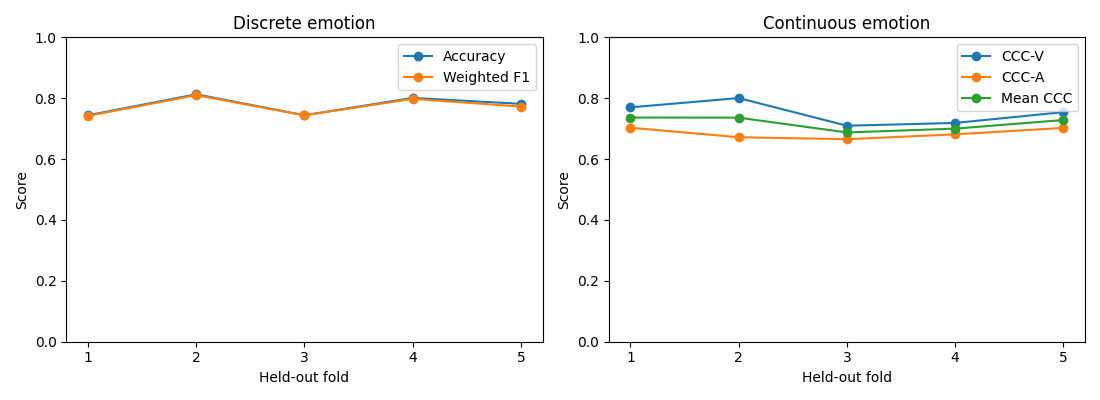

In [27]:
# 6-1. 5개 시험 폴드의 점수를 분류와 회귀 그래프로 나누어 표시함.
# 가로축은 시험 폴드 번호이며, 실제 폴드별 점수를 표시함.
FIGURES = OUT / "figures"
FIGURES.mkdir(exist_ok=True)
fold_numbers = np.arange(1, 6)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for key, label in [("accuracy", "Accuracy"), ("weighted_f1", "Weighted F1")]:
    axes[0].plot(fold_numbers, [r[key] for r in independent_rows], marker="o", label=label)
for key, label in [("ccc_valence", "CCC-V"), ("ccc_arousal", "CCC-A"), ("mean_ccc", "Mean CCC")]:
    axes[1].plot(fold_numbers, [r[key] for r in independent_rows], marker="o", label=label)
for ax, title in zip(axes, ["Discrete emotion", "Continuous emotion"]):
    ax.set(title=title, xlabel="Held-out fold", ylabel="Score", ylim=(0, 1), xticks=fold_numbers)
    ax.legend()
fig.tight_layout()
# 화면 확인용 PNG와 문서 삽입용 PDF에 같은 그래프를 저장함.
for extension in ("png", "pdf"):
    fig.savefig(FIGURES / f"fold_scores.{extension}")
plt.close(fig)
display(Image(filename=str(FIGURES / "fold_scores.png")))


## 6-2. 예시 대화의 정서가·각성도 정답·예측

4단계에서 사전에 정한 동일 대화의 결과를 발화 순서로 표시함.
점은 발화 단위 값이고 연결선은 순서를 보여주기 위한 시각적 보조임.
유효 V/A 마스크를 적용해 표시함.

**확인:** 사전에 고정한 예시 대화의 전체 발화를 순서대로 표시함.


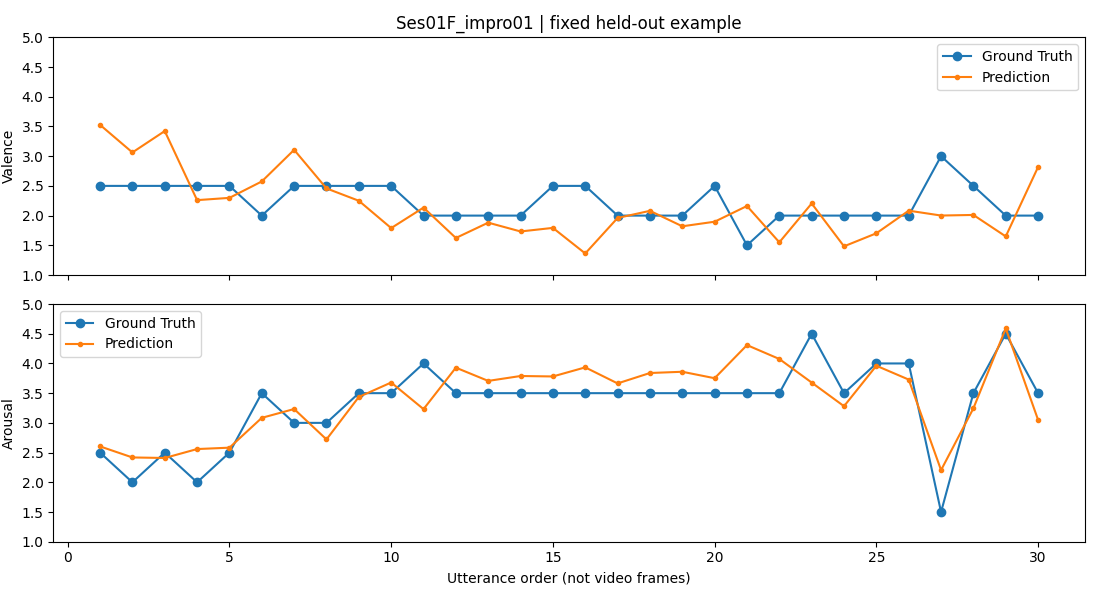

In [28]:
# 6-2. 사전에 고정한 예시 대화의 정서가·각성도를 발화 순서대로 비교함.
# 범위를 벗어난 정답은 그림용 복사본에서만 NaN으로 가리고, 원본 주석은 보존함.
valid = ((example_va_targets >= 1) & (example_va_targets <= 5)).all(1)
truth = example_va_targets.astype(float).copy()
truth[~valid] = np.nan
# 가로축은 발화 번호임.
utterance_order = np.arange(1, len(example_ids) + 1)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for dimension, (ax, title) in enumerate(zip(axes, ["Valence", "Arousal"])):
    # 정답과 예측을 동일 축에 그림. 연결선은 발화 순서를 표시함.
    ax.plot(utterance_order, truth[:, dimension], marker="o", label="Ground Truth")
    ax.plot(utterance_order, example_va_predictions[:, dimension], marker=".", label="Prediction")
    ax.set(ylabel=title, ylim=(1, 5))
    ax.legend()
axes[0].set_title(EXAMPLE_DIALOGUE + " | fixed held-out example")
axes[1].set_xlabel("Utterance order (not video frames)")
fig.tight_layout()
for extension in ("png", "pdf"):
    fig.savefig(FIGURES / f"example_va.{extension}")
plt.close(fig)
display(Image(filename=str(FIGURES / "example_va.png")))


# 7. 독립 검증과 결과 보존
## 7-1. 설명용 추론과 전체 평가의 예측 일치 확인

**실행 내용:** 4단계에서 직접 계산한 예시 대화 예측이 전체 평가 결과의 동일 발화 예측과 일치하는지 확인함.
설명 셀에서 생긴 전처리·가중치 연결 오류가 없는지 확인하는 단계임.

**확인:** 분류·V/A 모두 일치해야 함.


In [29]:
# 7-1. 설명용 함수와 전체 평가가 같은 모델·전처리를 사용했는지 검사함.
# 전체 폴드 결과에서 예시 발화 ID를 찾아 원래 예시 순서로 예측을 맞춤.
example_check = {}
for task, example_prediction in [("classification", example_class_predictions), ("va", example_va_predictions)]:
    with np.load(OUT / f"{task}_fold{EXAMPLE_FOLD}.npz", allow_pickle=False) as data:
        lookup = {uid: i for i, uid in enumerate(data["ids"])}
        positions = [lookup[uid] for uid in example_ids]
        full_prediction = data["predictions"][positions]
        difference = float(np.abs(full_prediction - example_prediction).max())
        # 예시 함수와 전체 평가의 동일 실행 조건을 비교하므로 절대 오차 1e-6, 상대 오차 0을 적용함.
        assert np.allclose(full_prediction, example_prediction, atol=1e-6, rtol=0)
        example_check[task] = {"passed": True, "max_abs_difference": difference}
show_table([{"과제": task, "일치": value["passed"], "최대 절대 차이": value["max_abs_difference"]} for task, value in example_check.items()])
# 표시 결과와 함께 실제 최대 차이를 검증 기록으로 남김.
demo.write(OUT / "notebook_example_audit.json", example_check)


과제,일치,최대 절대 차이
classification,True,0.0
va,True,0.0


## 7-2. 전체 저장 예측의 독립 감사

### 함수 `audit_demo.audit`
- **기능:** 실제 저장 예측을 독립적으로 채점하고 원래 확정된 예측과 대조함. ID·정답·채점 마스크·전체 OOF 중복 여부도 검사함.
- **입력 인자:** `output` — 이번 실행 결과 폴더 `OUT`.
- **반환값:** `audit_result` — 통과 여부와 폴드별 수치 차이. `independent_audit.json`도 저장함.

같은 저장 예측에서 다시 계산한 지표의 허용 오차는 `1e-10`임.
이전에 GPU로 계산한 예측과 현재 CPU 예측의 비교에는 32비트 부동소수점 연산 차이를 고려해 최대 절대 차이 `1e-4`를 적용하며,
분류 클래스 결정은 정확히 일치해야 함. 사전에 정한 허용 오차로 검증함.

**확인:** 10개 폴드와 10,039개 비교 행이 `PASS`로 출력되어야 함.


In [30]:
# 7-2. 전체 저장 예측을 별도 채점 구현과 원본 정답·과거 확정 예측으로 검증함.
# audit는 independent_audit.json을 결과 폴더에 기록하고 검사 요약을 반환함.
# 과거 예측은 재현성 비교에만 쓰며 이번 모델의 입력으로 사용하지 않음.
audit_result = audit_demo.audit(OUT)
assert audit_result["passed"]
show_table([{"독립 검증": audit_result["passed"], "비교 발화 수": audit_result["comparison_rows"],
             "과거 예측 대비 최대 절대 차이": audit_result["max_abs_prediction_difference"]}])


PASS | 10 folds | 10039 comparison rows | max prediction difference 1.1920929e-06


독립 검증,비교 발화 수,과거 예측 대비 최대 절대 차이
True,10039,1.1920928955078125e-06


## 7-3. 전체 정답 비교표와 결과 파일 확인

`utterance_comparison.csv`에는 전체 10,039개 발화의 이산·연속 정답과 예측, 채점 여부가 포함됨.
`report.html`은 폴드·발화 ID·텍스트를 검색할 수 있는 비교 화면임. 노트북을 저장하면 셀 아래 출력도 함께 보존됨.

| 보존 파일 | 내용 |
|---|---|
| `summary.json`, `summary.txt`, `fold_metrics.csv` | 전체 지표와 폴드별 점수 |
| `classification_fold*.npz`, `va_fold*.npz`, `*_oof.npz` | 이번 실행 예측, 정답, 발화 ID, 채점 마스크 |
| `utterance_comparison.csv`, `report.html` | 전체 발화의 정답·예측 비교 |
| `figures/` | 폴드별 성능과 예시 V/A 그래프 PNG/PDF |
| `preflight.json`, `notebook_example_audit.json`, `independent_audit.json` | 파일·예시 추론·전체 채점의 검증 결과 |

**확인:** 아래 출력 경로의 폴더 전체를 보존함.


In [31]:
# 7-3. 전체 발화의 정답·예측 비교표를 읽고 결과가 저장된 위치를 안내함.
# CSV는 한글을 지원하는 UTF-8 BOM 형식이며, 표시한 일부 행 외 전체 행도 파일에 보존됨.
with (OUT / "utterance_comparison.csv").open(encoding="utf-8-sig", newline="") as f:
    comparison_rows = list(csv.DictReader(f))
# 채점 제외 발화까지 포함한 전체 10,039개 행이 보존되었는지 확인함.
assert len(comparison_rows) == 10039
show_table(comparison_rows, columns=["fold", "utterance_id", "original_emotion", "predicted_emotion_ko", "classification_valid", "gt_valence", "pred_valence", "gt_arousal", "pred_arousal", "va_valid"], limit=10)
print("결과 폴더:", OUT)
print("전체 비교 화면:", OUT / "report.html")
print("전체 비교표:", OUT / "utterance_comparison.csv")
print("완료: 학습 없이 실제 추론 및 독립 채점까지 수행했습니다.")

# 현장에서 재계산한 전처리·특징 연결의 확인 기록을 결과와 함께 보존함.
preprocessing_check = dict(passed=True, utterance_id=MEDIA_EXAMPLE["id"],
    raw_audio_sha256=demo.sha(MEDIA_AUDIO_PATH), video_sha256=demo.sha(MEDIA_VIDEO_PATH),
    preprocessing_manifest_sha256=demo.sha(PREPROCESSING_ROOT / "manifest.json"),
    live_operations=["audio_loading", "prosody", "tokenization", "image_transform", "feature_pooling", "train_normalization"],
    pretrained_forward="prepared_intermediate_outputs", feature_comparison=preprocessing_comparison)
(OUT / "preprocessing_example_audit.json").write_text(json.dumps(preprocessing_check, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("미디어·전처리 확인 기록:", OUT / "preprocessing_example_audit.json")


fold,utterance_id,original_emotion,predicted_emotion_ko,classification_valid,gt_valence,pred_valence,gt_arousal,pred_arousal,va_valid
1,Ses01F_impro01_F000,neu,중립,True,2.5,3.5269718170166016,2.5,2.6039226055145264,True
1,Ses01F_impro01_F001,neu,중립,True,2.5,3.422826051712036,2.5,2.4091248512268066,True
1,Ses01F_impro01_F002,neu,중립,True,2.5,2.298638105392456,2.5,2.582813024520874,True
1,Ses01F_impro01_F003,xxx,중립,False,2.5,3.1068170070648193,3.0,3.2330474853515625,True
1,Ses01F_impro01_F004,xxx,중립,False,2.5,2.4576995372772217,3.0,2.7215828895568848,True
1,Ses01F_impro01_F005,neu,분노,True,2.5,1.7897793054580688,3.5,3.679283618927002,True
1,Ses01F_impro01_F006,fru,분노,False,2.0,1.8812352418899536,3.5,3.7062206268310547,True
1,Ses01F_impro01_F007,fru,분노,False,2.5,1.793341875076294,3.5,3.781114101409912,True
1,Ses01F_impro01_F008,fru,분노,False,2.0,1.9604259729385376,3.5,3.6640632152557373,True
1,Ses01F_impro01_F009,fru,분노,False,2.0,1.8201802968978882,3.5,3.860114097595215,True


전체 10,039행 중 앞 10행 표시
결과 폴더: /tmp/iemocap_notebook_mwgi2tia/IEMOCAP_Official_Demo/results/notebook_20261111_170934_748212
전체 비교 화면: /tmp/iemocap_notebook_mwgi2tia/IEMOCAP_Official_Demo/results/notebook_20261111_170934_748212/report.html
전체 비교표: /tmp/iemocap_notebook_mwgi2tia/IEMOCAP_Official_Demo/results/notebook_20261111_170934_748212/utterance_comparison.csv
완료: 학습 없이 실제 추론 및 독립 채점까지 수행했습니다.
미디어·전처리 확인 기록: /tmp/iemocap_notebook_mwgi2tia/IEMOCAP_Official_Demo/results/notebook_20261111_170934_748212/preprocessing_example_audit.json


# 8. 현장 설명 문구

> 학습이 완료된 이산 감정 분류 모델과 연속 감정 회귀 모델의 폴드별 가중치를 불러옴.
> IEMOCAP의 5개 세션으로 구성한 5겹 교차검증에서 각 폴드의 학습·개발에 사용하지 않은 시험 세션의 멀티모달 특징을 입력함.
> 예측 감정 클래스와 원본 감정 라벨을 비교해 가중 F1을 산출함.
> 예측 정서가·각성도와 원본 발화별 주석을 비교해 각 차원의 CCC 및 평균 CCC를 산출함.
> 현장에서는 학습 완료 가중치로 추론과 채점을 수행함.

**평가 범위:** IEMOCAP 통제 환경의 발화 단위 이산 감정 및 정서가·각성도 평가임.
분류와 회귀는 별도로 학습한 모델을 사용하며, 발화 ID로 두 과제의 정답·예측을 연결함.
대표 결과는 5개 폴드의 산술평균 ± 표본표준편차로 보고함.
